# Active subspaces of a four-chamber heart electromechanics model, from cell to organ

Stored data from

M. Strocchi, S. Longobardi, C. M. Augustin, M. A. F. Gsell, A. Petras, C. A. Rinaldi, E. J. Vigmond, G. Plank,
C. J. Oates, R. D. Wilkinson and S. A. Niederer, *Cell to whole organ global sensitivity analysis on a
four-chamber heart electromechanics model using Gaussian processes emulators*, PLOS Computational Biology
19(6):e1011257, 2023. [doi:10.1371/journal.pcbi.1011257](https://doi.org/10.1371/journal.pcbi.1011257)

1 School of Biomedical Engineering and Imaging Sciences, King's College London, London, United Kingdom;
2 National Heart and Lung Institute, Imperial College London, London, United Kingdom; 3 Medical University
of Graz, Graz, Austria; 4 BioTechMed-Graz, Graz, Austria; 5 Johann Radon Institute for Computational and
Applied Mathematics (RICAM), Linz, Austria; 6 Guy's and St Thomas' NHS Foundation Trust, London, United
Kingdom; 7 University of Bordeaux, CNRS, Bordeaux, Talence, France; 8 IHU Liryc, Bordeaux, Talence, France;
9 Newcastle University, Newcastle upon Tyne, United Kingdom; 10 University of Nottingham, Nottingham, United
Kingdom; 11 Alan Turing Institute, London, United Kingdom. (Strocchi 1,2; Longobardi 1; Augustin 3,4;
Gsell 3; Petras 5; Rinaldi 1,6; Vigmond 7,8; Plank 3,4; Oates 9; Wilkinson 10; Niederer 1,2,11.)

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 1257                       # the only seed: every bootstrap and permutation below draws from it
t_start = time.perf_counter()
warnings.simplefilter('once', ac.ValidityWarning)

## Summary

Strocchi et al. ran a patient-specific four-chamber heart electromechanics simulator (CARP coupled to the
CircAdapt circulation, about 3,250 core-hours per run) at the 407 successful points of a 500-point design in a
45-parameter space (30 parameters confined to a history-matched region) and deposited the inputs and 20
pressure-volume features; with $M = 407$ far below the $(m+1)(m+2)/2 = 1081$ coefficients of a full quadratic,
the notebook uses the linear (OLS) estimator, which gives one direction $w_1$ per output and no eigenvalue gap.
A linear function of the inputs predicts every feature with leave-one-out $R^2$ 0.731–0.963 (the direction
refitted in each fold), and a polynomial in the one variable $w_1^\top z$ does no better (0.938 for LV peak
pressure, whose linear fit gets 0.711 of its variance from the systemic resistance), so each feature varies
mainly along one direction of the sampled region; how much it varies in other directions is not identified by
407 runs (a ridge-penalized quadratic gives $\lambda_1/\lambda_2$ anywhere from 140.6 to 684.7 for LV peak
pressure at equally good LOO error), except that the two end-diastolic pressures have a stable second
direction, the atrioventricular delay. A second study on the ToR-ORd ventricular cell model (29 inputs, 2175
runs, QPHD) finds one-dimensional subspaces for all four calcium-transient features
($\lambda_1/\lambda_2$ = 14.4–50.7), with a stable CaMK second direction for diastolic calcium and the 90 %
relaxation time.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients the subspace is estimated from values: the linear least-squares estimator (OLS)
fits $f \approx c + \mathbf{u}^\top\mathbf{x}$ and takes $w_1 = \mathbf{u}/\|\mathbf{u}\|$ (one direction
only), and the global quadratic estimator (QPHD) fits a quadratic and averages the outer product of its
gradient. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter
Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Simulator** (paper, Methods, pp. 3–11). A four-chamber heart mesh built from one patient's CT. Electrical
activation is a reaction-Eikonal model without diffusion (Eq. 1):

$$\sqrt{\nabla t_a(\mathbf{x})^\top \mathbf{V}(\mathbf{x})\, \nabla t_a(\mathbf{x})} = 1 \ \ (\mathbf{x} \in \Omega),
\qquad t_a(\mathbf{x}) = t_0 \ \ (\mathbf{x} \in \Gamma),$$

with conduction velocities $CV_{f,v}$, $CV_{f,a}$ along the fibres, a fast endocardial layer (factor
$k_{FEC}$), a Bachmann-bundle region (factor $k_{BB}$) and an atrioventricular delay $AV_{delay}$. Each
myocyte's action potential is the ToR-ORd model (ventricles) or the Courtemanche model (atria); its calcium
transient drives the Land active-tension model. Passive tissue is the transversely isotropic Guccione law
(Eq. 2):

$$\Psi(\mathbf{E}) = \frac{a}{2}\left[e^{Q} - 1\right] + \frac{\kappa}{2}(\log J)^2,\qquad
Q = b_f E_{ff}^2 + 2 b_{ft}(E_{fs}^2 + E_{fn}^2) + b_t(E_{ss}^2 + E_{nn}^2 + 2E_{sn}^2),$$

with $\kappa = 1000$ kPa; the pericardium is a field of normal springs of stiffness $k_{peri}$, and the
cavities are coupled to the CircAdapt 0-D circulation (resistances $R_{sys}$, $R_{pulm}$, aorta length and
stiffness). Each run simulates 5 beats at a cycle length of 854 ms (Newton iterations limited to 1 for beats
1–3 and 2 for beats 4–5, linear-solver tolerance $10^{-4}$, time steps 0.02 ms ionic and 1.0 ms mechanics)
on 512 cores with CARP: on average 6 h 20 min, 3247 core-hours per run (p. 17).

**Parameter screening** (pp. 14–16, Fig. 5). Of 117 candidate parameters, sub-model sensitivity analyses
(ToR-ORd-Land, Courtemanche-Land, tissue electrophysiology, passive mechanics, CircAdapt) kept 45. The 30
cell and tissue parameters among them were restricted by history matching (HM) to regions where calcium and
tension transients and total activation times are physiological; their ranges are the plausible region of
the last HM wave, not a box. The other 15 have interval ranges (Tables 1–3). The cell below lists all 45 in
the column order of the data file.

**Quantities of interest** (p. 16, Table 4): 20 features of the last beat. For each ventricle, end-diastolic
volume (EDV) and pressure (EDP), end-systolic volume (ESV), peak pressure ($p_{max}$), and maximum and
minimum $dp/dt$; for each atrium, EDV before atrial contraction, ESV at its end, maximum volume during the
v-wave ($EDV_{vwave}$) and peak pressure during atrial contraction. Volumes in mL, pressures in mmHg (units
inferred, see DATA.md). The headline output is **LV peak pressure** `pmax_LV`, the first quantity of Fig. 6
and Fig. 9.

In [2]:
# The 45 inputs of the four-chamber study, in the column order of fourchamber_inputs.csv.
# group, description (Tables 1-3 of the paper), and the paper's range: an interval, or 'HM' when the
# range is the plausible region of a history-matching wave on a sub-model (S2-S4 Files).
INPUTS = [
    ('PCa', 'ToR-ORd', 'L-type Ca2+ current conductance', 'HM'),
    ('TRPN_v', 'ToR-ORd', 'max troponin C concentration [TRPN]', 'HM'),
    ('GNCX', 'ToR-ORd', 'Na+-Ca2+ exchanger conductance', 'HM'),
    ('Tref_v', 'Land, ventricle', 'reference isometric tension', 'HM'),
    ('TRPN50_v', 'Land, ventricle', 'CaTRPN at 50% blocked cross-bridges', 'HM'),
    ('nTm_v', 'Land, ventricle', 'Hill coefficient, Ca2+-troponin and U', 'HM'),
    ('nTRPN_v', 'Land, ventricle', 'Ca2+-troponin cooperativity', 'HM'),
    ('rs_v', 'Land, ventricle', 'steady-state duty ratio', 'HM'),
    ('rw_v', 'Land, ventricle', 'steady-state ratio W to S', 'HM'),
    ('Aeff_v', 'Land, ventricle', 'velocity-dependence distortion scale', 'HM'),
    ('ku_v', 'Land, ventricle', 'blocked-to-unblocked transition rate', 'HM'),
    ('ca50_v', 'Land, ventricle', 'reference Ca2+ sensitivity', 'HM'),
    ('mu_v', 'Land, ventricle', 'W-to-S transition rate scaling', 'HM'),
    ('Iup_max_a', 'Courtemanche', 'max Ca2+ uptake rate into network SR', 'HM'),
    ('Trpn_max_a', 'Courtemanche', 'total troponin C concentration', 'HM'),
    ('gCaL_a', 'Courtemanche', 'L-type Ca2+ current conductance', 'HM'),
    ('Tref_a', 'Land, atria', 'reference isometric tension', 'HM'),
    ('TRPN50_a', 'Land, atria', 'CaTRPN at 50% blocked cross-bridges', 'HM'),
    ('nTm_a', 'Land, atria', 'Hill coefficient, Ca2+-troponin and U', 'HM'),
    ('nTRPN_a', 'Land, atria', 'Ca2+-troponin cooperativity', 'HM'),
    ('rs_a', 'Land, atria', 'steady-state duty ratio', 'HM'),
    ('rw_a', 'Land, atria', 'steady-state ratio W to S', 'HM'),
    ('Aeff_a', 'Land, atria', 'velocity-dependence distortion scale', 'HM'),
    ('phi_a', 'Land, atria', 'distortion decay', 'HM'),
    ('ca50_a', 'Land, atria', 'reference Ca2+ sensitivity', 'HM'),
    ('mu_a', 'Land, atria', 'W-to-S transition rate scaling', 'HM'),
    ('CVf_v', 'Eikonal EP', 'ventricular CV along fibres', 'HM'),
    ('kFEC', 'Eikonal EP', 'CV factor of fast endocardial layer', 'HM'),
    ('CVf_a', 'Eikonal EP', 'atrial CV along fibres', 'HM'),
    ('kBB', 'Eikonal EP', 'CV factor of Bachmann bundle', 'HM'),
    ('AVdelay', 'Eikonal EP', 'atrioventricular delay', (100.0, 200.0)),
    ('Rsys', 'CircAdapt', 'systemic resistance scaling factor', (1.0, 4.0)),
    ('Rpulm', 'CircAdapt', 'pulmonary resistance scaling factor', (1.0, 4.0)),
    ('lAo', 'CircAdapt', 'length of the aorta', (300.0, 500.0)),
    ('kAo', 'CircAdapt', 'stiffness of the aorta', (6.0, 10.0)),
    ('a_v', 'Guccione, ventricle', 'bulk myocardium stiffness a', (0.5, 1.5)),
    ('bt_v', 'Guccione, ventricle', 'stiffness in transverse plane b_t', (1.5, 4.5)),
    ('a_a', 'Guccione, atria', 'bulk myocardium stiffness a', (1.5, 2.5)),
    ('bf_a', 'Guccione, atria', 'stiffness in fibre direction b_f', (4.0, 12.0)),
    ('bt_a', 'Guccione, atria', 'stiffness in transverse plane b_t', (1.5, 4.5)),
    ('kperi', 'boundary', 'pericardium spring stiffness', (0.5e-3, 2.0e-3)),  # paper [0.5, 2.0] kPa/mm
    ('EDPshift_LV', 'boundary', 'shift of LV end-diastolic pressure', (3.0, 9.0)),
    ('EDPunload_RV', 'boundary', 'RV end-diastolic (unloading) pressure', (3.0, 8.0)),
    ('aLvRv', 'LV-RV scaling', 'RV/LV scaling of bulk stiffness a', (1.0, 2.0)),
    ('TrefLvRv', 'LV-RV scaling', 'RV/LV scaling of Tref', (0.5, 1.0)),
]
NAMES = [r[0] for r in INPUTS]
m = len(NAMES)
print(f"{'#':>2s} {'name':13s} {'group':20s} {'paper range':>22s}  description")
for i, (n, g, d, r) in enumerate(INPUTS):
    rng_txt = 'HM (implicit)' if r == 'HM' else f'[{r[0]:g}, {r[1]:g}]'
    print(f'{i:2d} {n:13s} {g:20s} {rng_txt:>22s}  {d}')
print(f'\n{m} inputs: {sum(r[3] == "HM" for r in INPUTS)} with history-matched (implicit) ranges, '
      f'{sum(r[3] != "HM" for r in INPUTS)} with interval ranges')

 # name          group                           paper range  description
 0 PCa           ToR-ORd                       HM (implicit)  L-type Ca2+ current conductance
 1 TRPN_v        ToR-ORd                       HM (implicit)  max troponin C concentration [TRPN]
 2 GNCX          ToR-ORd                       HM (implicit)  Na+-Ca2+ exchanger conductance
 3 Tref_v        Land, ventricle               HM (implicit)  reference isometric tension
 4 TRPN50_v      Land, ventricle               HM (implicit)  CaTRPN at 50% blocked cross-bridges
 5 nTm_v         Land, ventricle               HM (implicit)  Hill coefficient, Ca2+-troponin and U
 6 nTRPN_v       Land, ventricle               HM (implicit)  Ca2+-troponin cooperativity
 7 rs_v          Land, ventricle               HM (implicit)  steady-state duty ratio
 8 rw_v          Land, ventricle               HM (implicit)  steady-state ratio W to S
 9 Aeff_v        Land, ventricle               HM (implicit)  velocity-dependence distort

Units are in the column names of `fourchamber_inputs.csv`; the paper states units only for $AV_{delay}$
(ms), $l_{Ao}$ (mm), the stiffnesses $a$ (kPa), $k_{peri}$ (kPa/mm) and the two pressures (mmHg). The stored
$k_{peri}$ is the paper's value times $10^{-3}$ (0.0005–0.002 against [0.5, 2.0] kPa/mm, presumably kPa/µm,
the length unit of CARP).

## Load the data

Four CSV files, converted losslessly from the Zenodo record 10.5281/zenodo.7405335 by `convert_data.py`:
the 407 successful four-chamber runs (45 inputs, 20 outputs) and, for the second study, the 2175 runs of the
ToR-ORd ionic model (29 inputs, 4 outputs). Rows of an inputs file and its outputs file correspond.

In [3]:
def read(path):
    """Values and the column names / units from the second '#' line of one of this data set's CSVs."""
    with open(path) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    return (np.loadtxt(path, delimiter=','), [c.split(' [')[0] for c in cols],
            [c.split(' [')[1].rstrip(']') for c in cols])


X, xnames, XUNITS = read('fourchamber_inputs.csv')       # 407 x 45, physical units
F, QOIS, FUNITS = read('fourchamber_outputs.csv')         # 407 x 20
XC, CNAMES, _ = read('torord_ionic_inputs.csv')           # 2175 x 29 (second study)
FC, CQOIS, CUNITS = read('torord_ionic_outputs.csv')      # 2175 x 4
assert xnames == NAMES
M = X.shape[0]
UNITS = dict(zip(QOIS, FUNITS))
print('four-chamber: inputs', X.shape, 'outputs', F.shape)
print('ToR-ORd ionic: inputs', XC.shape, 'outputs', FC.shape)

four-chamber: inputs (407, 45) outputs (407, 20)
ToR-ORd ionic: inputs (2175, 29) outputs (2175, 4)


### Design, and checks of the data

The paper's design (p. 16): Latin hypercube samples of the 15 interval parameters were combined with the
plausible samples of the last HM waves, and `psa_select` (python library diversipy) picked 500 space-filling,
"uniformly distributed" points from the plausible region. Of the 500 runs, 42 failed during unloading and 51
during the coupled simulation (p. 17); the 407 that finished are the data. The failed points are not
deposited, so the 407 rows are a subset of the design that the failures may bias; the next cell
shows that they do.

In [4]:
lo, hi = X.min(axis=0), X.max(axis=0)
print('duplicate input rows:', M - len(np.unique(X, axis=0)))
kurt = ((X - X.mean(0))**4).mean(0) / X.var(0)**2
print('\nInterval inputs: sample range against the paper range (kperi: paper value x 1e-3)')
for i, (n, g, d, r) in enumerate(INPUTS):
    if r != 'HM':
        inside = r[0] <= lo[i] and hi[i] <= r[1]
        cover = (hi[i] - lo[i]) / (r[1] - r[0])
        print(f'  {n:13s} [{lo[i]:.5g}, {hi[i]:.5g}]  inside: {inside}  covers {100 * cover:.1f}% '
              f'of the paper range  kurtosis {kurt[i]:.2f}')
hm = np.array([r[3] == 'HM' for r in INPUTS])
print(f'\nkurtosis (uniform 1.8): interval inputs {kurt[~hm].min():.2f}-{kurt[~hm].max():.2f}, '
      f'history-matched inputs {kurt[hm].min():.2f}-{kurt[hm].max():.2f}')
av = X[:, NAMES.index('AVdelay')]
print(f'AVdelay: {len(np.unique(av))} distinct values, all whole ms: {bool(np.all(av == np.round(av)))}')
R = np.corrcoef(X.T)
iu = np.triu_indices(m, 1)
order = np.argsort(-np.abs(R[iu]))[:5]
print('largest input correlations: ' + '; '.join(
    f'{NAMES[iu[0][k]]}-{NAMES[iu[1][k]]} {R[iu][k]:+.2f}' for k in order))
print(f'input pairs with |r| > 0.3: {int(np.sum(np.abs(R[iu]) > 0.3))} of {len(iu[0])}')
c = {q: F[:, j] for j, q in enumerate(QOIS)}
for s in ('LV', 'RV', 'LA', 'RA'):
    assert np.all(c['ESV_' + s] < c['EDV_' + s])
print('\nESV < EDV in all rows for all four chambers')
print(f"rows with LV peak pressure below 80 mmHg: {int(np.sum(c['pmax_LV'] < 80))} "
      f"(min {c['pmax_LV'].min():.1f} mmHg); LV ejection fraction "
      f"{(1 - c['ESV_LV'] / c['EDV_LV']).min():.2f}-{(1 - c['ESV_LV'] / c['EDV_LV']).max():.2f}")
print(f"rows with LA maximum v-wave volume below LA EDV: {int(np.sum(c['EDVvwave_LA'] < c['EDV_LA']))}")
print('\nSelection by the failed runs: quartile counts of the 15 interval inputs on the paper range '
      f'(about {M / 4:.0f} each if uniform) and the Kolmogorov-Smirnov p-value against U(paper range)')
KS = {}
for i, (n, g, d, r) in enumerate(INPUTS):
    if r != 'HM':
        t01 = (X[:, i] - r[0]) / (r[1] - r[0])
        cnt = np.histogram(t01, bins=[0, 0.25, 0.5, 0.75, 1 + 1e-12])[0]
        KS[n] = stats.kstest(t01, 'uniform').pvalue
        print(f'  {n:13s} ' + ' / '.join(f'{k:3d}' for k in cnt) + f'   KS p = {KS[n]:.3f}')
print('KS p < 0.05:', ', '.join(f'{n} ({KS[n]:.3f})' for n in KS if KS[n] < 0.05),
      f'| smallest p of the other {sum(KS[n] >= 0.05 for n in KS)}: {min(KS[n] for n in KS if KS[n] >= 0.05):.3f}')

duplicate input rows: 0

Interval inputs: sample range against the paper range (kperi: paper value x 1e-3)
  AVdelay       [100, 199]  inside: True  covers 99.0% of the paper range  kurtosis 1.81
  Rsys          [1.0017, 3.9937]  inside: True  covers 99.7% of the paper range  kurtosis 1.90
  Rpulm         [1.002, 3.998]  inside: True  covers 99.9% of the paper range  kurtosis 1.79
  lAo           [300.48, 498.75]  inside: True  covers 99.1% of the paper range  kurtosis 1.83
  kAo           [6.0118, 9.9894]  inside: True  covers 99.4% of the paper range  kurtosis 1.87
  a_v           [0.50061, 1.4998]  inside: True  covers 99.9% of the paper range  kurtosis 1.90
  bt_v          [1.5049, 4.4925]  inside: True  covers 99.6% of the paper range  kurtosis 1.84
  a_a           [1.5095, 2.4999]  inside: True  covers 99.0% of the paper range  kurtosis 1.84
  bf_a          [4.0492, 11.997]  inside: True  covers 99.3% of the paper range  kurtosis 1.99
  bt_a          [1.5192, 4.4989]  inside: Tru

The 15 interval inputs lie inside the paper's ranges and cover 98.9–99.9 % of them, with kurtosis 1.79–1.99
(1.8 for a uniform law). Kurtosis hides a selection effect, though: four of them are not uniform on their
range (Kolmogorov–Smirnov p = 0.005 for $AV_{delay}$, 0.008 for $a_v$, 0.003 for $a_a$, 0.011 for $b_{f,a}$;
the other 11 have p ≥ 0.201), and in each the lowest quartile is under-filled (80, 73, 83 and 72 rows against
about 102). The design was space-filling before the 93 runs failed, so the failures seem to concentrate at
low passive stiffness ($a_v$, $a_a$, $b_{f,a}$) and a short AV delay. The failed points are not deposited:
**everything below, the subspaces included, describes the model conditional on a run succeeding.**
($AV_{delay}$ takes whole milliseconds, 97 distinct values, so its KS p-value is approximate.) The 30
history-matched inputs have kurtosis 1.81–3.88: their marginals are not uniform, and they are correlated
through the HM constraints (13 of the 990 pairs have $|r| > 0.3$; the largest are $CV_{f,v}$–$k_{FEC}$, −0.86,
both set by the ventricular activation time, and $I_{up,max}$–$[Trpn]_{max}$, +0.76). The outputs are
physically consistent (ESV < EDV in every chamber and row). The paper notes that some runs have a low,
unphysiological LV peak pressure and kept them (p. 17): 48 rows are below 80 mmHg (minimum 58.0 mmHg), and in
35 rows the LA maximum v-wave volume is below the LA EDV. **Rule: all 407 rows are used**, as in the paper's
emulator training; none is dropped.

## Estimate the active subspace

**Scaling.** The inputs have no common box: 30 of them live on an implicit HM region. One rule is applied to
all 45: each input is mapped to $[-1, 1]$ by its own sample minimum and maximum (`ac.Uniform(lo, hi)`; X is
passed in physical units and v1 normalizes once). The space only fixes this scaling; the density of the
analysis is the empirical distribution of the 407 rows, which is not uniform on that box. A later cell
repeats the fit with every input scaled by its own standard deviation instead.

**What the coordinates mean.** The density is the empirical distribution of the 407 rows on the HM region, in
min–max coordinates that are *not whitened*: the history-matched inputs stay correlated. An entry of $w_1$ is
a partial slope, the change of the linear fit when one input moves and all others are held fixed; for
correlated inputs that move leaves the plausible region, and large entries of correlated inputs can cancel
inside it. The eigenvector section therefore reports, beside the weights, how much of the variance of the
linear fit, $\mathrm{Var}(\mathbf{u}^\top\mathbf{z})$ over the 407 rows, each group of inputs carries; these
shares do not depend on the scaling rule.

**Estimator.** There are no gradients. A full quadratic in 45 inputs has $(m+1)(m+2)/2 = 1081$ coefficients,
so QPHD (which needs $M \ge 1081$, and twice that by the repository rule) is not supported by $M = 407$, and
neither are local linear gradients (each needs $\ge m+1 = 46$ near neighbours in 45 dimensions). The notebook
therefore uses **OLS with $n = 1$** (`estimator='ols'`, 500 bootstrap replicates, `rng=SEED`) for all 20
outputs, and reports for each its in-sample and leave-one-out (LOO) $R^2$, the 95 % quantile of the in-sample
$R^2$ when the output is randomly permuted (200 permutations: what a linear fit with 46 coefficients achieves
on 407 rows of pure noise), and the bootstrap mean distance of $w_1$.

In [5]:
space = ac.Uniform(lo, hi, names=NAMES)   # one rule for all 45 inputs: [sample min, max] -> [-1, 1]
Z = space.to_normalized(X)

subs = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for j, q in enumerate(QOIS):
        subs[q] = ac.active_subspace(space=space, X=X, f=F[:, j], estimator='ols', n=1, nboot=500,
                                     bootstrap_vectors=1, rng=SEED, qoi=q)
print('v1 warnings:', sorted({f'{w.category.__name__}: {str(w.message)[:110]}' for w in caught}))

A1 = np.column_stack([np.ones(M), Z])
Q1, _ = np.linalg.qr(A1)
h1 = np.sum(Q1**2, axis=1)                  # leverages of the linear fit
U_OLS = np.linalg.lstsq(A1, F, rcond=None)[0][1:]   # 45 x 20: OLS slopes u in the normalized inputs


def linear_r2(f):
    """In-sample and leave-one-out R^2 of the least-squares linear fit in the 45 normalized inputs."""
    r = f - Q1 @ (Q1.T @ f)
    tss = np.sum((f - f.mean())**2)
    return 1 - r @ r / tss, 1 - np.sum((r / (1 - h1))**2) / tss


rng = np.random.default_rng(SEED)
LIN = {}
print(f"\n{'QoI':12s} {'units':7s} {'R2':>6s} {'LOO R2':>7s} {'null95':>7s} {'boot d1':>8s}  largest entries of w1")
for j, q in enumerate(QOIS):
    f = F[:, j]
    r2, loo = linear_r2(f)
    null = np.quantile([linear_r2(rng.permutation(f))[0] for _ in range(200)], 0.95)
    w = subs[q].W[:, 0]
    top = np.argsort(-np.abs(w))[:4]
    LIN[q] = dict(r2=r2, loo=loo, null=null, d1=subs[q].bootstrap_distances[:, 0].mean())
    print(f"{q:12s} {UNITS[q]:7s} {r2:6.3f} {loo:7.3f} {null:7.3f} {LIN[q]['d1']:8.3f}  "
          + ', '.join(f'{NAMES[k]} {w[k]:+.2f}' for k in top))
loos = np.array([LIN[q]['loo'] for q in QOIS])
print(f'\nlinear LOO R^2 over the 20 outputs: {loos.min():.3f} to {loos.max():.3f} (median {np.median(loos):.3f})')

v1 warnings: ["ValidityWarning: outside the method's assumptions; estimator 'ols' on a uniform space: needs the linearity condition, which the"]

QoI          units       R2  LOO R2  null95  boot d1  largest entries of w1
EDV_LV       mL       0.936   0.918   0.153    0.122  EDPshift_LV -0.49, Rpulm -0.36, Rsys +0.32, ca50_v +0.32
EDP_LV       mmHg     0.875   0.841   0.145    0.148  Rpulm -0.45, ca50_a -0.37, Rsys +0.35, gCaL_a +0.34
ESV_LV       mL       0.951   0.938   0.144    0.109  Rsys +0.53, EDPshift_LV -0.42, ca50_v +0.41, TRPN50_v +0.30
pmax_LV      mmHg     0.951   0.938   0.145    0.107  Rsys +0.63, ca50_v -0.28, TRPN50_v -0.25, Tref_v +0.24
dpdt_max_LV  mmHg/s   0.835   0.789   0.147    0.186  rs_v -0.40, Rsys +0.38, Tref_v +0.36, ku_v +0.30
dpdt_min_LV  mmHg/s   0.806   0.752   0.156    0.213  Rsys -0.47, Tref_v -0.37, TRPN_v +0.30, rs_v +0.27
EDV_RV       mL       0.964   0.954   0.154    0.103  EDPunload_RV -0.68, Rsys -0.46, EDPshift_LV +0.27, Rpulm +0.21
EDP_RV       

pmax_RA      mmHg     0.884   0.852   0.150    0.134  Rsys -0.51, ca50_a -0.36, TRPN50_a -0.32, gCaL_a +0.32

linear LOO R^2 over the 20 outputs: 0.731 to 0.963 (median 0.862)


v1 warns that OLS on a uniform space needs a linearity condition; here the linear fit itself is good, so the
direction is meaningful as the gradient of the best linear approximation. The linear fit explains most of the
variance of every output: LOO $R^2$ from 0.731 (ESV_RA) to 0.963 (ESV_RV), median 0.862, while permuted
outputs reach an in-sample $R^2$ of only 0.138–0.156 (95 % quantile). This LOO $R^2$ is honest for the
direction: leaving a row out refits all 46 coefficients, hence $w_1$. The bootstrap mean distance of $w_1$ is
0.089–0.234, so the leading entries are well determined, the small ones less so.

**A penalized quadratic: a check of $w_1$, and an illustration of what 407 rows cannot decide.** OLS has a
single nonzero eigenvalue, $\|\mathbf{u}\|^2$, so it cannot measure a gap. The cells below fit a partially
penalized quadratic: the intercept and the 45 linear terms are free, and the 1035 squares and cross products
carry a ridge penalty $\lambda\|\beta\|^2$ (as $\lambda \to \infty$ the fit is the OLS fit); $\mathbf{C}$ is the
average of $\nabla q\, \nabla q^\top$ of the fitted quadratic $q$ over the 407 rows. With 1081 coefficients and
407 rows the curvature is not identified: the penalty decides how much of it the fit keeps, and so how large
$\lambda_2, \lambda_3, \dots$ are. Besides the fit at the penalty with the best exact LOO error (grid of 73
values), the cell therefore reports the range of $\lambda_1/\lambda_2$ and of the share of $E\|\nabla q\|^2$
off the first direction, $1 - \lambda_1/\sum_k\lambda_k$, over all *LOO-equivalent* penalties (LOO $R^2$
within 0.005 of the best). These ranges show what the data leave open; they are not estimates of a gap. A
null test asks whether there is any curvature at all: the OLS fit plus a random permutation of the OLS
residuals (an exactly linear function with exchangeable noise), refitted with its own LOO choice of penalty
(100 replicates per output). Rejecting it says that the outputs are not exactly linear; it says nothing about
the size of $\lambda_1/\lambda_2$.

In [6]:
JU, KU = np.triu_indices(m, k=1)
LAMS = np.logspace(-3, 6, 73)             # ridge penalties searched by exact leave-one-out error


def quad_block(Zs):
    """The 45 squares and 990 cross products of the normalized inputs."""
    return np.hstack([Zs * Zs, Zs[:, JU] * Zs[:, KU]])


def prepare(Zs):
    """Factorizations of the design that every fit on the rows Zs reuses."""
    A = np.column_stack([np.ones(len(Zs)), Zs])
    QA, _ = np.linalg.qr(A)
    B = quad_block(Zs)
    PB = B - QA @ (QA.T @ B)              # quadratic columns with the linear part projected out
    U, s, Vt = np.linalg.svd(PB, full_matrices=False)
    return dict(Z=Zs, A=A, QA=QA, hA=np.sum(QA**2, axis=1), B=B, PB=PB, U=U, s=s, Vt=Vt)


def as_matrix(P, alpha, beta):
    """Eigenpairs of C = mean of grad q grad q^T over the rows, for q = alpha . [1, z] + beta . quad(z)."""
    H = np.diag(beta[:m])
    H[JU, KU] += beta[m:] / 2
    H[KU, JU] += beta[m:] / 2
    G = alpha[1:][None, :] + 2 * P['Z'] @ H
    lam, W = np.linalg.eigh(G.T @ G / len(G))
    return lam[::-1], W[:, ::-1]


def pr_quadratic(P, f, lam=None):
    """Partially penalized quadratic: [1, z] free, ridge penalty lam*||beta||^2 on the 1035 quadratic
    coefficients. lam=None picks lam on LAMS by the exact leave-one-out error (hat-matrix formula),
    among the penalties whose largest leverage is at most 0.99.
    Returns the LOO R^2, lam, and the eigenvalues and eigenvectors of C of the fitted quadratic."""
    Pf = f - P['QA'] @ (P['QA'].T @ f)
    Uf = P['U'].T @ Pf
    tss = np.sum((f - f.mean())**2)
    best = None
    for L in (LAMS if lam is None else [lam]):
        g = P['s']**2 / (P['s']**2 + L)
        h = P['hA'] + (P['U']**2) @ g
        if h.max() > 0.99:                # near-interpolation: the LOO formula is 0/0, skip this penalty
            continue
        e = (Pf - P['U'] @ (g * Uf)) / (1 - h)
        if best is None or e @ e < best[0]:
            best = (e @ e, L)
    if best is None:                      # no admissible penalty (only when lam is given)
        return None
    L = best[1]
    beta = P['Vt'].T @ (P['s'] / (P['s']**2 + L) * Uf)
    alpha = np.linalg.lstsq(P['A'], f - P['B'] @ beta, rcond=None)[0]
    lam_C, W = as_matrix(P, alpha, beta)
    return 1 - best[0] / tss, L, lam_C, W


def distance(W1, W2, k):
    """Subspace distance ||W1 W1^T - W2 W2^T||_2 (sine of the largest principal angle) for k columns."""
    sv = np.linalg.svd(W1[:, :k].T @ W2[:, :k], compute_uv=False)
    return float(np.sqrt(max(0.0, 1 - sv.min()**2)))


PZ = prepare(Z)
print(f'quadratic: {1 + m + PZ["B"].shape[1]} coefficients ({PZ["B"].shape[1]} penalized), {M} rows')

quadratic: 1081 coefficients (1035 penalized), 407 rows


In [7]:
rng = np.random.default_rng(SEED)
TOL = 0.005        # "LOO-equivalent" penalties: LOO R^2 within TOL of the best penalty on the grid
RQ = {}
print(f"{'QoI':12s} {'LOO lin':>7s} {'LOO quad':>8s} {'lam':>6s} {'LOO-equiv. lam':>14s} {'l1/l2':>6s} "
      f"{'l1/l2 over equiv.':>17s} {'off-w1 %':>11s} {'min|w.w|':>8s} {'null rej.':>9s}")
for j, q in enumerate(QOIS):
    f = F[:, j]
    loo, L, lam_C, W = pr_quadratic(PZ, f)
    sweep = []                            # (penalty, LOO R^2, eigenvalues, eigenvectors) on the whole grid
    for Ls in LAMS:
        out = pr_quadratic(PZ, f, lam=Ls)
        if out is not None:
            sweep.append((Ls, out[0], out[2], out[3]))
    eq = [s for s in sweep if s[1] >= loo - TOL]
    r12_eq = np.array([s[2][0] / s[2][1] for s in eq])
    off_eq = np.array([1 - s[2][0] / s[2].sum() for s in eq])     # share of E||grad q||^2 off w1
    cos_eq = np.array([abs(s[3][:, 0] @ subs[q].W[:, 0]) for s in eq])
    # null: the linear fit plus permuted linear residuals: exactly linear, exchangeable noise
    flin = Q1 @ (Q1.T @ f)
    res = f - flin
    nul, nul_lam = [], []
    for _ in range(100):
        _, Ln, ln, _ = pr_quadratic(PZ, flin + rng.permutation(res))
        nul.append(ln[1] / ln[0])
        nul_lam.append(Ln)
    RQ[q] = dict(loo=loo, lam=L, ev=lam_C, W=W, null95=np.quantile(nul, 0.95), null_lam=np.array(nul_lam),
                 cos=abs(W[:, 0] @ subs[q].W[:, 0]), sweep=sweep, eq=eq, r12_eq=r12_eq, off_eq=off_eq,
                 cos_eq=cos_eq)
    print(f"{q:12s} {LIN[q]['loo']:7.3f} {loo:8.3f} {L:6.3g} {eq[0][0]:6.3g}-{eq[-1][0]:<7.3g} "
          f"{lam_C[0] / lam_C[1]:6.1f} {r12_eq.min():8.1f}-{r12_eq.max():<8.1f} "
          f"{100 * off_eq.min():4.1f}-{100 * off_eq.max():<5.1f} {cos_eq.min():8.3f} "
          f"{str(lam_C[1] / lam_C[0] > RQ[q]['null95']):>9s}")
gain = np.array([RQ[q]['loo'] - LIN[q]['loo'] for q in QOIS])
fac = np.array([RQ[q]['r12_eq'].max() / RQ[q]['r12_eq'].min() for q in QOIS])
coss = np.array([RQ[q]['cos_eq'].min() for q in QOIS])
nl = np.concatenate([RQ[q]['null_lam'] for q in QOIS])
print(f'\nLOO R^2 gain of the quadratic (best penalty) over the linear fit: {gain.min():.3f} to {gain.max():.3f}')
print(f'lambda1/lambda2 over the LOO-equivalent penalties changes by a factor {fac.min():.1f} to {fac.max():.1f} '
      f'(median {np.median(fac):.1f}) within one output')
offs = np.concatenate([RQ[q]['off_eq'] for q in QOIS])
print(f'share of E||grad q||^2 off w1 over all outputs and LOO-equivalent penalties: {100 * offs.min():.1f} '
      f'to {100 * offs.max():.1f} %')
r23 = {q: RQ[q]['ev'][1] / RQ[q]['ev'][2] for q in QOIS}
print('lambda2/lambda3 at the chosen penalty: ' + ', '.join(f'{q} {r23[q]:.2f}' for q in ('EDP_LV', 'EDP_RV'))
      + f'; the other 18: {min(r23[q] for q in QOIS if not q.startswith("EDP")):.2f} to '
      f'{max(r23[q] for q in QOIS if not q.startswith("EDP")):.2f}')
print(f'|w1(quadratic) . w1(OLS)| over all LOO-equivalent penalties and outputs: {coss.min():.3f} to '
      f'{max(RQ[q]["cos_eq"].max() for q in QOIS):.3f}')
print('no-curvature null rejected (lambda2/lambda1 above its 95% quantile):',
      sum(RQ[q]['ev'][1] / RQ[q]['ev'][0] > RQ[q]['null95'] for q in QOIS), 'of', len(QOIS),
      f'| penalty chosen under the null: median {np.median(nl):.3g}, >= 1e4 in {np.mean(nl >= 1e4):.0%} '
      f'of {len(nl)} replicates')

QoI          LOO lin LOO quad    lam LOO-equiv. lam  l1/l2 l1/l2 over equiv.    off-w1 % min|w.w| null rej.


EDV_LV         0.918    0.947    7.5   1.33-42.2     163.0    129.7-344.2     1.6-4.1      0.996      True


EDP_LV         0.841    0.893    7.5   1.33-31.6      57.6     47.0-98.3      3.2-7.0      0.992      True


ESV_LV         0.938    0.962   4.22   1.33-42.2     146.0    129.3-360.2     1.3-3.4      0.998      True


pmax_LV        0.938    0.955    7.5   1.33-75       183.1    140.6-684.7     0.8-4.0      0.991      True


dpdt_max_LV    0.789    0.844   17.8   4.22-42.2      49.2     32.0-80.9      4.1-10.0     0.974      True


... (11 outputs left out)

EDV_RA         0.825    0.848   56.2   17.8-133      161.6     76.9-378.2     1.8-8.1      0.993      True


ESV_RA         0.731    0.793   31.6   17.8-56.2     402.2    307.8-578.6     1.1-2.1      0.997      True


EDVvwave_RA    0.932    0.950   13.3   1.33-75       153.9     98.3-475.6     1.1-5.1      0.996      True


pmax_RA        0.852    0.875   56.2   23.7-178      424.9    233.7-1414.3    0.5-2.7      0.996      True

LOO R^2 gain of the quadratic (best penalty) over the linear fit: 0.011 to 0.065
lambda1/lambda2 over the LOO-equivalent penalties changes by a factor 1.9 to 12.3 (median 4.5) within one output
share of E||grad q||^2 off w1 over all outputs and LOO-equivalent penalties: 0.3 to 10.2 %
lambda2/lambda3 at the chosen penalty: EDP_LV 4.20, EDP_RV 4.38; the other 18: 1.15 to 2.25
|w1(quadratic) . w1(OLS)| over all LOO-equivalent penalties and outputs: 0.969 to 1.000
no-curvature null rejected (lambda2/lambda1 above its 95% quantile): 20 of 20 | penalty chosen under the null: median 1e+06, >= 1e4 in 54% of 2000 replicates


Curvature exists: for every output the penalized quadratic predicts better than the linear fit (LOO $R^2$
higher by 0.011–0.065), and the no-curvature null is rejected for 20 of 20 (under the null the LOO choice
mostly pushes the penalty to the top of the grid: median $10^6$, $\ge 10^4$ in 54 % of 2000 replicates). Its
size relative to the main trend is not identified: within the LOO-equivalent penalties of one output,
$\lambda_1/\lambda_2$ changes by a factor 1.9 to 12.3 (median 4.5), e.g. 140.6–684.7 for pmax_LV and
25.3–47.9 for EDP_RV. **The notebook therefore quotes no eigenvalue ratio for the four-chamber study.** What
the data do fix is the first direction, $|w_1^\top \hat w_1|$ = 0.969–1.000 against OLS over all
LOO-equivalent penalties, and a rough bound on the variation off it: 0.3–10.2 % of $E\|\nabla q\|^2$ over all
outputs and LOO-equivalent penalties (0.8–4.0 % for pmax_LV, 5.4–10.2 % for EDP_RV).

#### A second direction for the end-diastolic pressures

At the chosen penalty $\lambda_2/\lambda_3$ is 4.20 for EDP_LV and 4.38 for EDP_RV, against 1.15–2.25 for the
other 18 outputs. The cell checks whether these second directions are stable: over the LOO-equivalent
penalties, over 25 subsamples of 80 % of the rows at the full-data penalty, and with a penalty-free fit (the
linear model plus one term, the square of the normalized AV delay).

In [8]:
# The two outputs with the largest lambda2/lambda3 of the penalized quadratic: is w2 stable?
iav = NAMES.index('AVdelay')
rng = np.random.default_rng(SEED)
for q in ('EDP_LV', 'EDP_RV'):
    f = F[:, QOIS.index(q)]
    W, ev = RQ[q]['W'], RQ[q]['ev']
    r23_eq = [s[2][1] / s[2][2] for s in RQ[q]['eq']]
    av_eq = [abs(s[3][iav, 1]) for s in RQ[q]['eq']]
    r23, d2, avs = [], [], []
    for b in range(25):                   # 25 subsamples of 80 % at the full-data penalty
        idx = rng.choice(M, int(0.8 * M), replace=False)
        _, _, lb, Wb = pr_quadratic(prepare(Z[idx]), f[idx], lam=RQ[q]['lam'])
        r23.append(lb[1] / lb[2])
        d2.append(distance(W, Wb, 2))
        avs.append(abs(Wb[iav, 1]))
    print(f"{q}: lambda2/lambda3 = {ev[1] / ev[2]:.2f} at the chosen penalty, {min(r23_eq):.2f}-{max(r23_eq):.2f} "
          f"over the LOO-equivalent penalties; w2: " + ', '.join(f'{NAMES[i]} {W[i, 1]:+.2f}' for i in
                                                                    np.argsort(-np.abs(W[:, 1]))[:3]))
    print(f"   |w2 entry of AVdelay| over the LOO-equivalent penalties {min(av_eq):.2f}-{max(av_eq):.2f}; "
          f"25 subsamples: lambda2/lambda3 2.5-97.5% [{np.percentile(r23, 2.5):.2f}, {np.percentile(r23, 97.5):.2f}], "
          f"mean 2-D subspace distance {np.mean(d2):.3f}, |AVdelay entry| >= {min(avs):.2f}")
# a penalty-free check: add one term, the square of the normalized AV delay, to the linear fit
A2 = np.column_stack([A1, Z[:, iav]**2])
Q2, _ = np.linalg.qr(A2)
h2 = np.sum(Q2**2, axis=1)
AVG = {}
for j, q in enumerate(QOIS):
    f = F[:, j]
    r = f - Q2 @ (Q2.T @ f)
    AVG[q] = 1 - np.sum((r / (1 - h2))**2) / np.sum((f - f.mean())**2) - LIN[q]['loo']
print('\nLOO R^2 of the linear fit plus z_AVdelay^2, gain over the linear fit: '
      + ', '.join(f"{q} {LIN[q]['loo']:.3f} -> {LIN[q]['loo'] + AVG[q]:.3f}" for q in ('EDP_LV', 'EDP_RV')))
print('outputs with a gain above 0.01:', ', '.join(f'{q} (+{AVG[q]:.3f})' for q in QOIS if AVG[q] > 0.01),
      f'| largest gain of the others: {max(AVG[q] for q in QOIS if AVG[q] <= 0.01):+.3f}')

EDP_LV: lambda2/lambda3 = 4.20 at the chosen penalty, 4.04-4.20 over the LOO-equivalent penalties; w2: AVdelay +0.83, kBB +0.20, nTRPN_a -0.16
   |w2 entry of AVdelay| over the LOO-equivalent penalties 0.82-0.83; 25 subsamples: lambda2/lambda3 2.5-97.5% [2.60, 3.57], mean 2-D subspace distance 0.207, |AVdelay entry| >= 0.76


EDP_RV: lambda2/lambda3 = 4.38 at the chosen penalty, 4.06-4.62 over the LOO-equivalent penalties; w2: AVdelay -0.80, nTRPN_a +0.22, phi_a -0.21
   |w2 entry of AVdelay| over the LOO-equivalent penalties 0.79-0.80; 25 subsamples: lambda2/lambda3 2.5-97.5% [2.89, 4.51], mean 2-D subspace distance 0.202, |AVdelay entry| >= 0.71

LOO R^2 of the linear fit plus z_AVdelay^2, gain over the linear fit: EDP_LV 0.841 -> 0.878, EDP_RV 0.745 -> 0.835
outputs with a gain above 0.01: EDP_LV (+0.038), EDP_RV (+0.089) | largest gain of the others: +0.001


Both end-diastolic pressures have a stable second direction, and it is the AV delay: its entry in $w_2$ has
magnitude 0.82–0.83 (EDP_LV) and 0.79–0.80 (EDP_RV) over the LOO-equivalent penalties and at least 0.76 and
0.71 in every subsample; $\lambda_2/\lambda_3$ has subsample 2.5–97.5 % ranges [2.60, 3.57] and [2.89, 4.51],
and the mean 2-D subspace distance is 0.207 and 0.202. The penalty-free fit confirms it: one extra term,
$z_{AV}^2$, raises the LOO $R^2$ from 0.841 to 0.878 (EDP_LV) and from 0.745 to 0.835 (EDP_RV), more than the
whole penalized quadratic gives for EDP_RV (0.810), while no other output gains more than 0.001. So the two
end-diastolic pressures are close to functions of two variables, the active variable $w_1^\top z$ and a curved
effect of the AV delay; the paper ranks the AV delay second for EDP_RV (Fig 8). v1's rule (n = 1 with OLS) is
unchanged; the second direction is a finding about these two outputs, not a different choice of n.

## Results

The headline output is LV peak pressure (`pmax_LV`). Its active direction is the OLS $w_1$. OLS has one nonzero
eigenvalue, so the eigenvalue panels show what the penalized quadratic adds and how that depends on the
penalty. The uncertainty of the quadratic's subspaces is measured by subsampling: 100 replicates of 80 % of
the rows, each with its own LOO-chosen penalty (a bootstrap would repeat rows, which breaks the LOO choice).

#### Eigenvalues

In [9]:
HEAD = 'pmax_LV'
jh = QOIS.index(HEAD)
fh = F[:, jh]
print(f'{HEAD}: OLS has one nonzero eigenvalue, lambda1 = ||u||^2 = {subs[HEAD].eigenvalues[0]:.1f} '
      f'(bootstrap 2.5-97.5% [{np.percentile(subs[HEAD].bootstrap_eigenvalues[:, 0], 2.5):.1f}, '
      f'{np.percentile(subs[HEAD].bootstrap_eigenvalues[:, 0], 97.5):.1f}]); lambda2 = ... = 0 by construction')
eqh = RQ[HEAD]['eq']
print(f'penalized quadratic, LOO-equivalent penalties {eqh[0][0]:.3g}-{eqh[-1][0]:.3g}: LOO R^2 '
      f'{min(s[1] for s in eqh):.4f}-{max(s[1] for s in eqh):.4f}, lambda1/lambda2 {RQ[HEAD]["r12_eq"].min():.1f}'
      f'-{RQ[HEAD]["r12_eq"].max():.1f}, lambda2/lambda3 {min(s[2][1] / s[2][2] for s in eqh):.2f}-'
      f'{max(s[2][1] / s[2][2] for s in eqh):.2f}, share off w1 {100 * RQ[HEAD]["off_eq"].min():.1f}-'
      f'{100 * RQ[HEAD]["off_eq"].max():.1f} %')
for s in RQ[HEAD]['sweep']:
    if s[0] in (eqh[0][0], RQ[HEAD]['lam'], eqh[-1][0]):
        print(f'   penalty {s[0]:7.3g}: LOO R^2 {s[1]:.4f}, lambda1/lambda2 {s[2][0] / s[2][1]:6.1f}, '
              f'eigenvalues 1-3 {np.array2string(s[2][:3], precision=3)}')
# Subsampling, not the bootstrap: a bootstrap replicate repeats rows, which breaks the leave-one-out choice
# of the penalty. Each replicate keeps a random 80% of the rows (without replacement), refits, and
# chooses its own penalty by leave-one-out.
rng = np.random.default_rng(SEED)
NS, MS = 100, int(0.8 * M)
sub_ev, sub_d, sub_lam = [], [], []
for b in range(NS):
    idx = rng.choice(M, MS, replace=False)
    _, Lb, lb, Wb = pr_quadratic(prepare(Z[idx]), fh[idx])
    sub_ev.append(lb[:10])
    sub_lam.append(Lb)
    sub_d.append([distance(RQ[HEAD]['W'], Wb, k) for k in range(1, 7)])
sub_ev, sub_d, sub_lam = np.array(sub_ev), np.array(sub_d), np.array(sub_lam)
r = sub_ev[:, 0] / sub_ev[:, 1]
print(f'{NS} subsamples of {MS} rows, own LOO penalty ({sub_lam.min():.3g}-{sub_lam.max():.3g}): lambda1/lambda2 '
      f'median {np.median(r):.1f}, 2.5-97.5% [{np.percentile(r, 2.5):.1f}, {np.percentile(r, 97.5):.1f}]; '
      f'rank correlation of the ratio with the chosen penalty {stats.spearmanr(sub_lam, r)[0]:.2f}')
print('subsample mean subspace distance to the full-data quadratic, k = 1..6:', np.array2string(sub_d.mean(0), precision=3))
print(f'OLS w1: bootstrap mean distance {subs[HEAD].bootstrap_distances[:, 0].mean():.3f} (500 replicates)')

pmax_LV: OLS has one nonzero eigenvalue, lambda1 = ||u||^2 = 1464.6 (bootstrap 2.5-97.5% [1296.6, 1705.1]); lambda2 = ... = 0 by construction
penalized quadratic, LOO-equivalent penalties 1.33-75: LOO R^2 0.9501-0.9547, lambda1/lambda2 140.6-684.7, lambda2/lambda3 1.48-1.67, share off w1 0.8-4.0 %
   penalty    1.33: LOO R^2 0.9541, lambda1/lambda2  140.6, eigenvalues 1-3 [1377.201    9.796    6.348]
   penalty     7.5: LOO R^2 0.9547, lambda1/lambda2  183.1, eigenvalues 1-3 [1397.753    7.632    4.692]
   penalty      75: LOO R^2 0.9501, lambda1/lambda2  684.7, eigenvalues 1-3 [1.440e+03 2.104e+00 1.421e+00]


100 subsamples of 325 rows, own LOO penalty (1.33-56.2): lambda1/lambda2 median 322.0, 2.5-97.5% [198.8, 578.3]; rank correlation of the ratio with the chosen penalty 0.94
subsample mean subspace distance to the full-data quadratic, k = 1..6: [0.067 0.348 0.76  0.712 0.733 0.819]
OLS w1: bootstrap mean distance 0.107 (500 replicates)


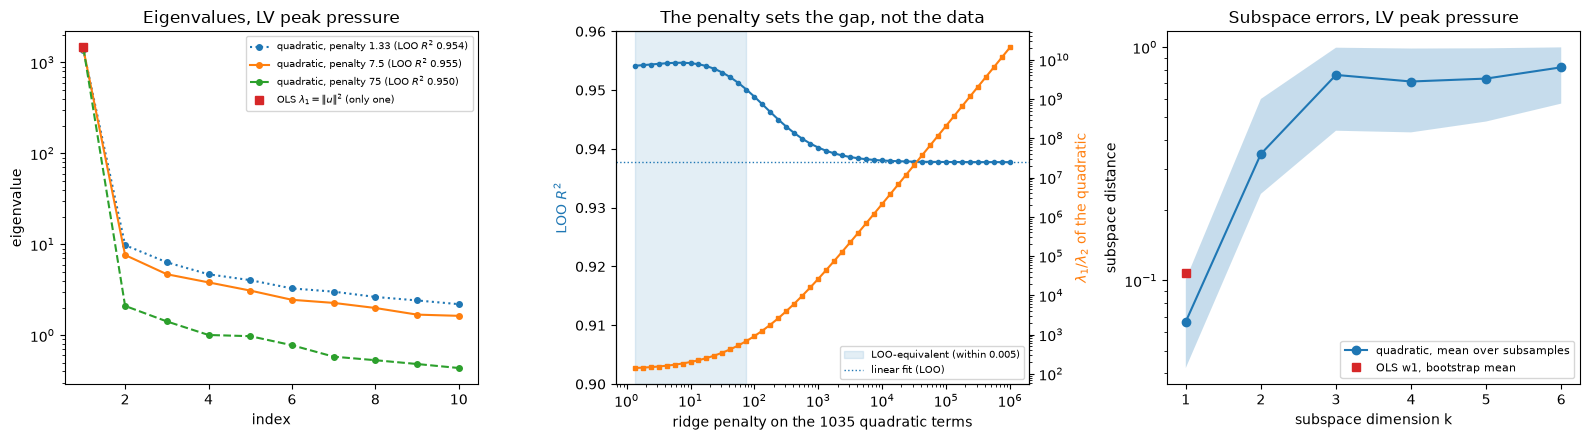

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
k = np.arange(1, 11)
ax = axes[0]
for s, ls in ((eqh[0], ':'), (min(RQ[HEAD]['sweep'], key=lambda s: abs(s[0] - RQ[HEAD]['lam'])), '-'),
              (eqh[-1], '--')):
    ax.semilogy(k, s[2][:10], 'o' + ls, ms=4, label=f'quadratic, penalty {s[0]:.3g} (LOO $R^2$ {s[1]:.3f})')
ax.semilogy([1], [subs[HEAD].eigenvalues[0]], 's', c='C3', label=r'OLS $\lambda_1 = \|u\|^2$ (only one)')
ax.set_xlabel('index')
ax.set_ylabel('eigenvalue')
ax.set_title('Eigenvalues, LV peak pressure')
ax.legend(fontsize=7)
ax = axes[1]
pen = np.array([s[0] for s in RQ[HEAD]['sweep']])
ax.semilogx(pen, [s[1] for s in RQ[HEAD]['sweep']], 'o-', ms=3, c='C0')
ax.axvspan(eqh[0][0], eqh[-1][0], color='C0', alpha=0.12, label=f'LOO-equivalent (within {TOL})')
ax.axhline(LIN[HEAD]['loo'], ls=':', c='C0', lw=1, label='linear fit (LOO)')
ax.set_xlabel('ridge penalty on the 1035 quadratic terms')
ax.set_ylabel('LOO $R^2$', color='C0')
ax.set_ylim(0.9, 0.96)
ax.legend(fontsize=7, loc='lower right')
ax2 = ax.twinx()
ax2.loglog(pen, [s[2][0] / s[2][1] for s in RQ[HEAD]['sweep']], 's-', ms=3, c='C1')
ax2.set_ylabel(r'$\lambda_1/\lambda_2$ of the quadratic', color='C1')
ax.set_title('The penalty sets the gap, not the data')
ax = axes[2]
ax.semilogy(np.arange(1, 7), sub_d.mean(0), 'o-', label='quadratic, mean over subsamples')
ax.fill_between(np.arange(1, 7), *np.percentile(sub_d, [2.5, 97.5], axis=0), alpha=0.25)
ax.semilogy([1], [subs[HEAD].bootstrap_distances[:, 0].mean()], 's', c='C3', label='OLS w1, bootstrap mean')
ax.set_xlabel('subspace dimension k')
ax.set_ylabel('subspace distance')
ax.set_title('Subspace errors, LV peak pressure')
ax.legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

OLS gives $\lambda_1 = \|\mathbf{u}\|^2 = 1464.6$ (bootstrap 2.5–97.5 %: 1296.6–1705.1) and nothing else; there
is no second eigenvalue to compare it with. The penalized quadratic's $\lambda_1$ is of the same size (1397.753
at the best penalty, 7.5), but $\lambda_2, \lambda_3, \dots$ follow the penalty (left and middle panels): over
the LOO-equivalent penalties 1.33–75, where the LOO $R^2$ stays within 0.9501–0.9547, $\lambda_1/\lambda_2$
goes from 140.6 to 684.7. The subsamples tell the same story: each picks its own penalty (1.33–56.2) and the
ratio follows it (rank correlation 0.94; median 322.0, 2.5–97.5 % [198.8, 578.3]). These ratios illustrate the
penalty, not a gap of the model. The robust statement is that the variation off $w_1$ is small, 0.8–4.0 % of
$E\|\nabla q\|^2$ over the LOO-equivalent penalties, with its exact size not identified.

#### Subspace errors

The right panel: the quadratic's first direction is determined (subsample mean distance 0.067, against 0.107
for the OLS bootstrap) and its two-dimensional subspace is not (0.348, with $\lambda_2/\lambda_3$ = 1.48–1.67
over the LOO-equivalent penalties): LV peak pressure has no stable second direction.

#### Eigenvectors

OLS w1 (f increases along w1): Rsys +0.635, ca50_v -0.276, TRPN50_v -0.249, Tref_v +0.240, TRPN50_a -0.205, Rpulm -0.200, ca50_a -0.194, rs_v -0.182
share of |w1|^2 on Rsys: 0.403; on the 26 cell-model inputs (0-25): 0.503; on the 4 Eikonal HM inputs: 0.002
entries whose bootstrap 95% interval excludes 0: 34 of 45

pmax_LV: group                  |w1|^2 mm |w1|^2 sd  separate joint var
          26 cell-model (0-25)       0.503     0.400     0.586     0.160
          4 Eikonal HM (26-29)       0.002     0.002     0.003     0.002
          15 interval (30-44)        0.495     0.598     0.876     0.829
          Rsys                       0.403     0.486     0.711     0.711
|cos(u, S u)| (u against the direction of Cov(z, f) = S u): pmax_LV 0.754
largest variance inflation factors: Iup_max_a 8.3, Trpn_max_a 7.1, ca50_v 6.3, gCaL_a 6.3, ca50_a 6.2; condition number of the input correlation matrix 65

QoI          |w1|^2 on cell  separate joint var |cos(u,Su)|
EDV_LV                0.433  

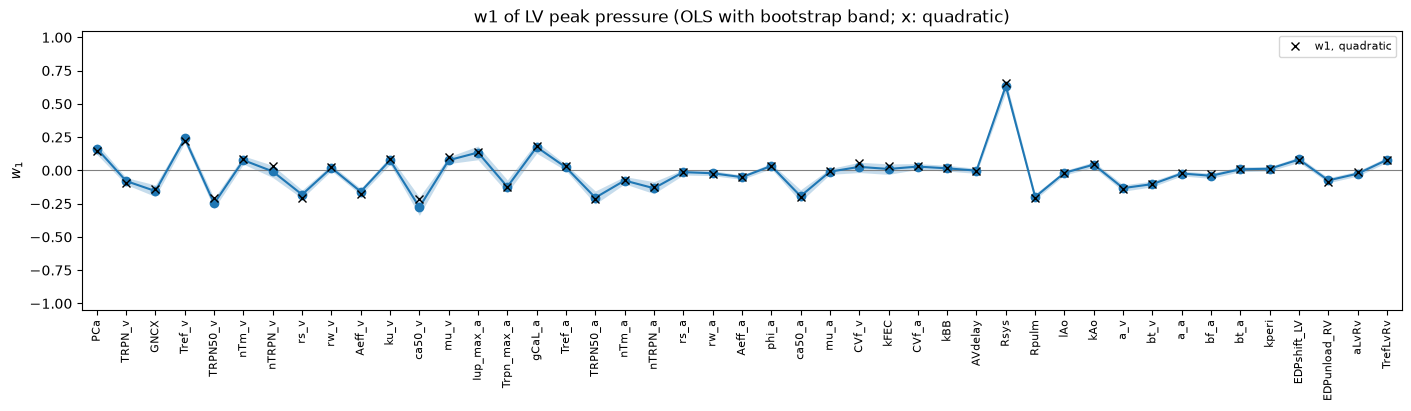

In [11]:
fig, ax = ac.plotting.plot_eigenvectors(subs[HEAD], indices=[0], labels=NAMES, interval='percentile',
                                     figsize=(14, 4))
a0 = np.atleast_1d(ax)[0]
w_q = RQ[HEAD]['W'][:, 0] * np.sign(RQ[HEAD]['W'][:, 0] @ subs[HEAD].W[:, 0])
a0.plot(np.arange(1, m + 1), w_q, 'x', c='k', label='w1, quadratic')   # components at 1..m
a0.set_title('w1 of LV peak pressure (OLS with bootstrap band; x: quadratic)')
a0.tick_params(axis='x', labelrotation=90, labelsize=8)
a0.legend(fontsize=8)
plt.close(fig)
w = subs[HEAD].W[:, 0]
print('OLS w1 (f increases along w1): ' + ', '.join(f'{NAMES[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:8]))
print(f'share of |w1|^2 on Rsys: {w[NAMES.index("Rsys")]**2:.3f}; on the 26 cell-model inputs (0-25): '
      f'{np.sum(w[:26]**2):.3f}; on the 4 Eikonal HM inputs: {np.sum(w[26:30]**2):.3f}')
lo95, hi95 = np.percentile(subs[HEAD].bootstrap_eigenvectors[:, :, 0], [2.5, 97.5], axis=0)
print('entries whose bootstrap 95% interval excludes 0:', int(np.sum((lo95 > 0) | (hi95 < 0))), 'of', m)

# Weights are partial slopes; with correlated inputs, report how much of Var(u^T z) each group carries.
S = np.cov(Z.T)                            # covariance of the 407 rows (min-max coordinates)
GROUPS = {'26 cell-model (0-25)': np.arange(26), '4 Eikonal HM (26-29)': np.arange(26, 30),
          '15 interval (30-44)': np.arange(30, 45), 'Rsys': np.array([NAMES.index('Rsys')])}
sdz = np.sqrt(np.diag(S))


def group_shares(u, G):
    """||w1||^2 share (min-max), ||w1||^2 share (sd scaling), sum of the separate variance contributions
    u_i^2 var(z_i) / Var(u^T z), and the joint share u_G^T S_GG u_G / Var(u^T z)."""
    V = u @ S @ u
    us = u * sdz
    return (np.sum(u[G]**2) / (u @ u), np.sum(us[G]**2) / (us @ us), np.sum(us[G]**2) / V,
            u[G] @ S[np.ix_(G, G)] @ u[G] / V)


uh = U_OLS[:, jh]
print(f'\n{HEAD}: {"group":22s} {"|w1|^2 mm":>9s} {"|w1|^2 sd":>9s} {"separate":>9s} {"joint var":>9s}')
for gname, G in GROUPS.items():
    print(f'          {gname:22s} ' + ' '.join(f'{v:9.3f}' for v in group_shares(uh, G)))
cos_su = lambda u: abs(u @ S @ u) / np.linalg.norm(u) / np.linalg.norm(S @ u)
print(f'|cos(u, S u)| (u against the direction of Cov(z, f) = S u): {HEAD} {cos_su(uh):.3f}')
Rc = np.corrcoef(Z.T)
vif = np.diag(np.linalg.inv(Rc))
print('largest variance inflation factors: ' + ', '.join(f'{NAMES[i]} {vif[i]:.1f}' for i in np.argsort(-vif)[:5])
      + f'; condition number of the input correlation matrix {np.linalg.cond(Rc):.0f}')
cell = GROUPS['26 cell-model (0-25)']
print(f"\n{'QoI':12s} {'|w1|^2 on cell':>14s} {'separate':>9s} {'joint var':>9s} {'|cos(u,Su)|':>11s}")
for j, q in enumerate(QOIS):
    sh = group_shares(U_OLS[:, j], cell)
    print(f'{q:12s} {sh[0]:14.3f} {sh[2]:9.3f} {sh[3]:9.3f} {cos_su(U_OLS[:, j]):11.3f}')
jv = np.array([group_shares(U_OLS[:, j], cell)[3] for j in range(len(QOIS))])
cs = np.array([cos_su(U_OLS[:, j]) for j in range(len(QOIS))])
print(f'joint variance share of the 26 cell-model inputs over the 20 outputs: {jv.min():.3f} to {jv.max():.3f}; '
      f'|cos(u, Su)| {cs.min():.3f} to {cs.max():.3f}')
fig

LV peak pressure increases along $w_1$: most strongly with the systemic resistance $R_{sys}$ (+0.635), then
decreases with the ventricular calcium sensitivity $ca_{50,v}$ (−0.276) and $TRPN_{50,v}$ (−0.249), increases
with the reference tension $T_{ref,v}$ (+0.240), and decreases with $TRPN_{50,a}$ and $R_{pulm}$ (−0.205,
−0.200); 34 of the 45 entries have a bootstrap 95 % interval that excludes zero, and the quadratic's first
eigenvector (crosses) follows the OLS entries closely.

**The weights overstate the cell-model inputs.** The 26 ToR-ORd, Courtemanche and Land entries hold 0.503 of
$\|w_1\|^2$ (0.400 with sd scaling), and their separate variance contributions add up to 0.586 of
$\mathrm{Var}(\mathbf{u}^\top\mathbf{z})$, but together they carry only 0.160 of it: they are correlated
(variance inflation factors up to 8.3, condition number of the input correlation matrix 65), and their partial
slopes largely cancel inside the HM region. $R_{sys}$, nearly uncorrelated with the others, carries 0.711, and
the 15 interval inputs together 0.829; the four Eikonal inputs carry 0.002. The direction along which the
linear fit varies within the sampled cloud, $\mathrm{Cov}(\mathbf{z}, f) = \boldsymbol\Sigma\mathbf{u}$, differs
from $\mathbf{u}$ ($|\cos|$ = 0.754). Over the 20 outputs the joint share of the cell-model inputs is
0.012–0.667 and $|\cos(\mathbf{u}, \boldsymbol\Sigma\mathbf{u})|$ 0.369–0.920; the extreme cases are ESV_RA
(joint 0.667 against a separate sum of 5.279, $|\cos|$ 0.369) and ESV_LA (0.306 against 2.293, 0.504), the
two outputs whose top input differs from the paper's ranking (comparison below).

#### Sufficient summary plots

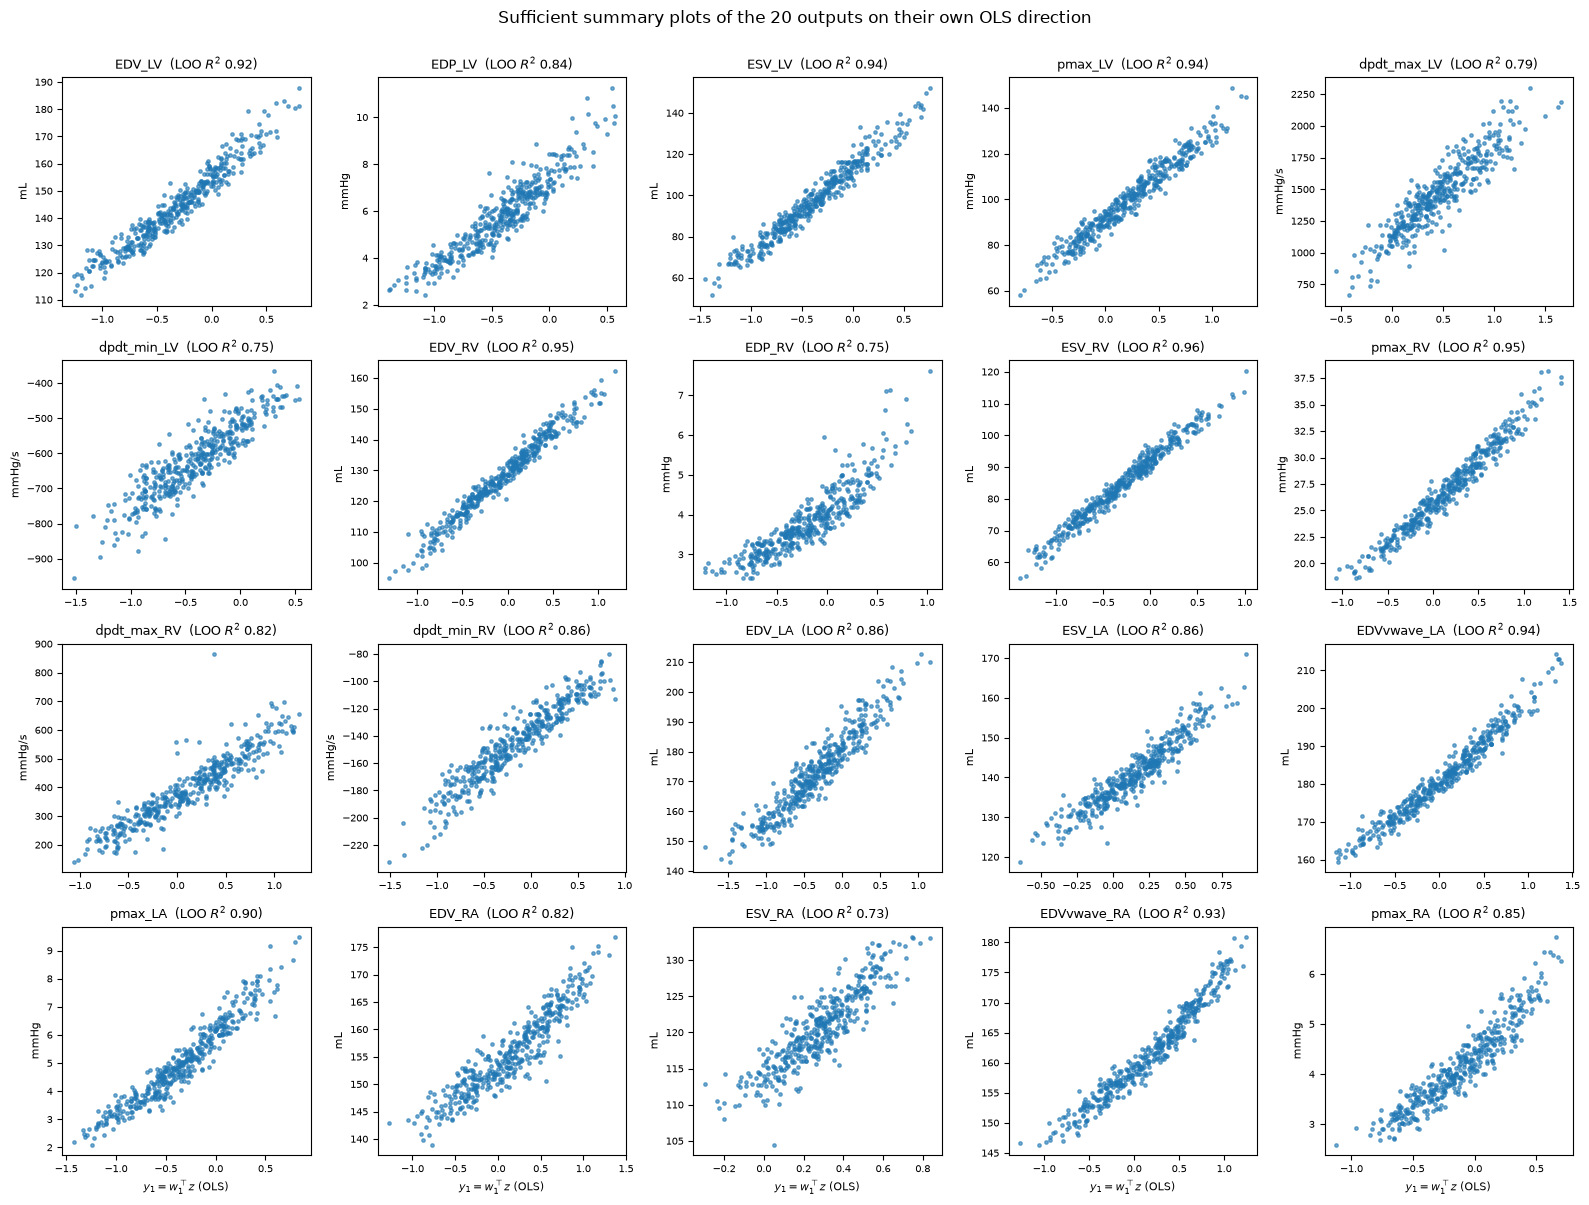

In [12]:
fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for ax, (j, q) in zip(axes.ravel(), enumerate(QOIS)):
    y = Z @ subs[q].W[:, 0]
    ax.scatter(y, F[:, j], s=6, alpha=0.6)
    ax.set_title(f"{q}  (LOO $R^2$ {LIN[q]['loo']:.2f})", fontsize=9)
    ax.set_ylabel(UNITS[q], fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[-1]:
    ax.set_xlabel(r'$y_1 = w_1^\top z$ (OLS)', fontsize=8)
fig.suptitle('Sufficient summary plots of the 20 outputs on their own OLS direction', y=1.0)
fig.tight_layout()
plt.close(fig)
fig

Every output collapses onto one active variable with a near-linear trend; the scatter about it is largest
where the linear LOO $R^2$ is lowest (ESV_RA, EDP_RV, dpdt_min_LV), and EDP_RV bends upward (convex);
part of its scatter is the AV-delay direction found above. The panel titles give the linear LOO
$R^2$.

#### Surrogate on the active variable

pmax_LV: LOO R^2 of a polynomial in y1, degree 1/2/3, w1 fixed (fit_surrogate): 0.951 / 0.951 / 0.950
pmax_LV: the same with w1 refitted in each fold:                     0.938 / 0.938 / 0.937
best 1-D polynomial LOO R^2 over the 20 outputs, w1 fixed: 0.792 (ESV_RA) to 0.971 (ESV_RV); w1 refitted: 0.737 (ESV_RA) to 0.964 (ESV_RV)
w1-refitted degree 1 equals the linear LOO R^2 for every output: True; largest gain of degree 2 or 3 over degree 1: EDP_RV +0.038, EDV_RA +0.018, pmax_RA +0.017


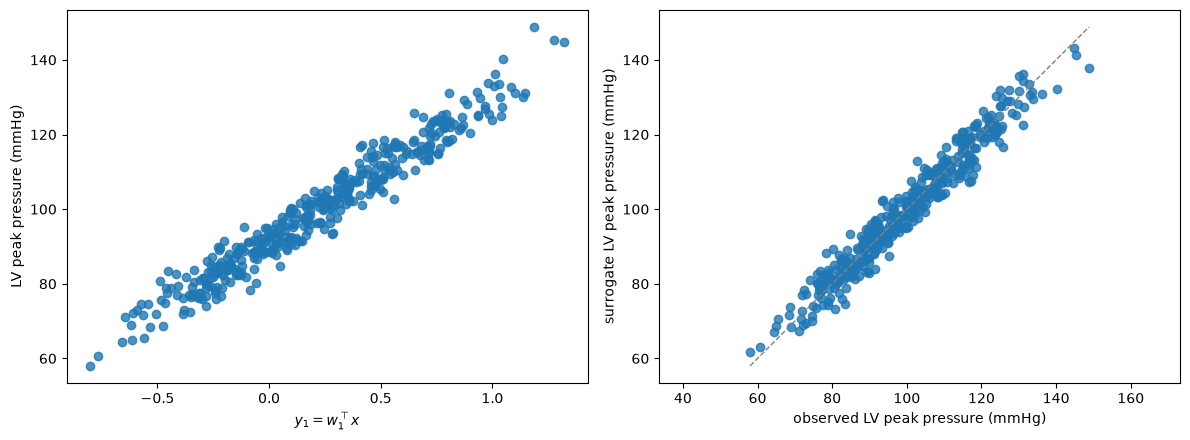

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(subs[HEAD], X=X, f=fh, qoi_label='LV peak pressure (mmHg)', ax=axes[0])
SUR = {}
for j, q in enumerate(QOIS):
    SUR[q] = {d: ac.fit_surrogate(X=X, f=F[:, j], subspace=subs[q], kind='poly', degree=d).loo_r_squared
              for d in (1, 2, 3)}
sur = ac.fit_surrogate(X=X, f=fh, subspace=subs[HEAD], kind='poly', degree=2)
ac.plotting.plot_surrogate_fit(sur, X=X, f=fh, qoi_label='LV peak pressure (mmHg)', ax=axes[1])
fig.tight_layout()
plt.close(fig)


def loo_refit(f, degrees=(1, 2, 3)):
    """LOO R^2 of a polynomial in y1 = w1^T z in which the OLS direction w1 is refitted without the
    held-out row (fit_surrogate's LOO keeps the full-data w1 fixed)."""
    err = np.zeros((len(degrees), M))
    for i in range(M):
        keep = np.arange(M) != i
        u = np.linalg.lstsq(A1[keep], f[keep], rcond=None)[0][1:]
        y = Z @ (u / np.linalg.norm(u))
        for a, d in enumerate(degrees):
            V = np.vander(y, d + 1)
            err[a, i] = f[i] - V[i] @ np.linalg.lstsq(V[keep], f[keep], rcond=None)[0]
    return {d: 1 - err[a] @ err[a] / np.sum((f - f.mean())**2) for a, d in enumerate(degrees)}


HON = {q: loo_refit(F[:, j]) for j, q in enumerate(QOIS)}
print(f'{HEAD}: LOO R^2 of a polynomial in y1, degree 1/2/3, w1 fixed (fit_surrogate): '
      + ' / '.join(f'{SUR[HEAD][d]:.3f}' for d in (1, 2, 3)))
print(f'{HEAD}: the same with w1 refitted in each fold:                     '
      + ' / '.join(f'{HON[HEAD][d]:.3f}' for d in (1, 2, 3)))
best = np.array([max(SUR[q].values()) for q in QOIS])
bh = np.array([max(HON[q].values()) for q in QOIS])
print(f'best 1-D polynomial LOO R^2 over the 20 outputs, w1 fixed: {best.min():.3f} ({QOIS[int(best.argmin())]}) '
      f'to {best.max():.3f} ({QOIS[int(best.argmax())]}); w1 refitted: {bh.min():.3f} ({QOIS[int(bh.argmin())]}) '
      f'to {bh.max():.3f} ({QOIS[int(bh.argmax())]})')
print(f'w1-refitted degree 1 equals the linear LOO R^2 for every output: '
      f'{all(abs(HON[q][1] - LIN[q]["loo"]) < 1e-9 for q in QOIS)}; largest gain of degree 2 or 3 over degree 1: '
      + ', '.join(f'{q} +{max(HON[q][2], HON[q][3]) - HON[q][1]:.3f}' for q in
                  sorted(QOIS, key=lambda q: -(max(HON[q][2], HON[q][3]) - HON[q][1]))[:3]))
fig

A polynomial in the single active variable $y_1$ predicts LV peak pressure with LOO $R^2$ 0.951 / 0.951 / 0.950
(degree 1/2/3) when $w_1$ is held at its full-data value, as `fit_surrogate` does; those values are
optimistic, since $w_1$ was fitted with the held-out row. Refitting the OLS direction in every fold gives
0.938 / 0.938 / 0.937: the trend along $y_1$ is linear, and the degree-1 value equals the LOO $R^2$ of the
linear fit in all 45 inputs, for every output, as it must. Over the 20 outputs the best honest value is 0.737
(ESV_RA) to 0.964 (ESV_RV), against 0.792–0.971 with $w_1$ fixed; the largest gain of a curved polynomial in
$y_1$ over a straight line is +0.038 (EDP_RV).

#### Does the scaling rule matter?

In [14]:
# Sensitivity to the scaling rule: the same OLS fit with every input scaled by its own sample standard
# deviation instead of its sample half-range (both rules treat all 45 inputs alike).
half = (hi - lo) / 2
sd = X.std(axis=0)
Aphys = np.column_stack([np.ones(M), X])
cosines = []
for j, q in enumerate(QOIS):
    u = np.linalg.lstsq(Aphys, F[:, j], rcond=None)[0][1:]      # physical gradient of the linear fit
    w_mm = u * half / np.linalg.norm(u * half)
    w_sd = u * sd / np.linalg.norm(u * sd)
    assert abs(abs(w_mm @ subs[q].W[:, 0]) - 1) < 1e-10        # same as v1's OLS direction
    cosines.append(abs(w_mm @ w_sd))
    same_top = np.argmax(np.abs(w_mm)) == np.argmax(np.abs(w_sd))
    if q == HEAD or not same_top:
        print(f'{q}: |w(half-range) . w(sd)| = {cosines[-1]:.3f}; top input {NAMES[np.argmax(np.abs(w_mm))]} '
              f'vs {NAMES[np.argmax(np.abs(w_sd))]}')
cosines = np.array(cosines)
print(f'{HEAD}, sd scaling: |w1|^2 share of Rsys {group_shares(uh, GROUPS["Rsys"])[1]:.3f}, '
      f'of the 26 cell-model inputs {group_shares(uh, cell)[1]:.3f}')
print(f'|w(half-range) . w(sd)| over the 20 outputs: {cosines.min():.3f} to {cosines.max():.3f}')
print(f'half-range / sd: interval inputs {np.min(half[~hm] / sd[~hm]):.2f}-{np.max(half[~hm] / sd[~hm]):.2f} '
      f'(sqrt(3) = 1.73 for a uniform), history-matched {np.min(half[hm] / sd[hm]):.2f}-{np.max(half[hm] / sd[hm]):.2f}')

pmax_LV: |w(half-range) . w(sd)| = 0.990; top input Rsys vs Rsys


dpdt_max_LV: |w(half-range) . w(sd)| = 0.992; top input rs_v vs Rsys
ESV_LA: |w(half-range) . w(sd)| = 0.992; top input ca50_a vs gCaL_a
ESV_RA: |w(half-range) . w(sd)| = 0.994; top input ca50_a vs gCaL_a
pmax_LV, sd scaling: |w1|^2 share of Rsys 0.486, of the 26 cell-model inputs 0.400
|w(half-range) . w(sd)| over the 20 outputs: 0.985 to 0.999
half-range / sd: interval inputs 1.70-1.86 (sqrt(3) = 1.73 for a uniform), history-matched 1.74-2.94


Scaling every input by its standard deviation instead of its half-range changes the directions little
($|w^\top w'|$ = 0.985–0.999). The interval inputs have half-range/sd 1.70–1.86, near $\sqrt 3$ for a
uniform law, but the history-matched ones reach 2.94, so the rule shifts weight between groups. For LV peak
pressure $R_{sys}$ leads under both rules (0.990), and the sd rule moves weight from the cell-model inputs
(0.400 of $\|w_1\|^2$, against 0.503) to $R_{sys}$ (0.486, against 0.403); the variance shares of the
eigenvector section do not depend on the rule. The top input changes for three outputs: dpdt_max_LV
($rs_v$ to $R_{sys}$) and ESV_LA and ESV_RA ($ca_{50,a}$ to $g_{CaL,a}$), where two or three inputs have
nearly equal weights.

## Second study: the ToR-ORd ventricular cell model

The first stage of the paper's screening (S2 File) ran the ToR-ORd ionic model alone with 29 conductances and
calcium-handling parameters and four features of the calcium transient: diastolic calcium (`Ca_diast`),
amplitude (`Ca_ampl`), time to peak (`TTP_Ca`) and 90 % relaxation time (`RT90_Ca`) (labels of the deposit;
units µM and ms inferred). The deposit has 2175 runs. The S2 File was not read; the ranges are inferred from
the data: for the 26 inputs with a value in Table 1, the sample minimum is 0.728–0.750 of that value and the
maximum 1.2475–1.2501 (the low end 0.728 is $P_{Nab}$, which, like $P_{Cab}$, is stored rounded to two
significant digits: 11 and 297 distinct values); $P_{Ca}$, $G_{NCX}$ and $[TRPN]$, marked HM in Table 1, span
0.750–1.250 of their ToR-ORd defaults (Tomek et al. 2019). So the box is the default $\times [0.75, 1.25]$ for
all 29 inputs. **This box is not the cell region of the four-chamber runs**: there $G_{NCX}$ spans 0.275–0.715
of its default, disjoint from the ionic box, and $P_{Ca}$ and $[TRPN]$ reach 1.838 and 1.754 of their
defaults (history matching with the Land model moved them; S2 File).
The marginals are uniform (kurtosis 1.80–1.82). The same scaling rule is used (sample min and max), and with
$M = 2175 \ge 2 \times 465$ the global quadratic estimator (QPHD) is supported; 200 bootstrap replicates,
`rng=SEED`, dimension by v1's default gap rule.

In [15]:
# Second study: the ToR-ORd ionic model (cell stage, S2 File), 29 inputs, 2175 runs.
TORORD_TABLE1 = {'GNa': 11.7802, 'GNaL': 0.0279, 'Gto': 0.16, 'GKr': 0.0321, 'GKs': 0.0011, 'GK1': 0.6992,
                 'GNaK': 15.4509, 'GCa': 5e-4, 'GKb': 0.0189, 'PNab': 1.9239e-09, 'PCab': 5.9194e-08,
                 'GClCa': 0.2843, 'GClb': 1.98e-03, 'Jrel': 1.5378, 'Jup': 1.0, 'INaCa_SS': 0.35,
                 'ICaL_SS': 0.8, 'aCaMK': 0.05, 'bCaMK': 0.00068, 'CaMKo': 0.05, 'CMDN': 0.05, 'BSR': 0.047,
                 'BSL': 1.124, 'CSQN': 10.0, 'tau_diffCa': 0.2, 'tau_tr': 60.0}     # Table 1 values
# Table 1 lists PCa, GNCX and [TRPN] as 'HM'; their ToR-ORd model defaults (Tomek et al. 2019):
TORORD_DEFAULT = {'PCa': 8.3757e-05, 'GNCX': 0.0034, 'TRPN': 0.07}
loc, hic = XC.min(axis=0), XC.max(axis=0)
rel = np.array([[loc[i] / TORORD_TABLE1[n], hic[i] / TORORD_TABLE1[n]]
                for i, n in enumerate(CNAMES) if n in TORORD_TABLE1])
print(f'sample min / Table 1 value: {rel[:, 0].min():.4f}-{rel[:, 0].max():.4f}; '
      f'max / Table 1 value: {rel[:, 1].min():.4f}-{rel[:, 1].max():.4f} ({len(rel)} inputs with a value)')
FOURCH = {'PCa': 'PCa', 'GNCX': 'GNCX', 'TRPN': 'TRPN_v'}      # ToR-ORd name -> four-chamber column
for n, d0 in TORORD_DEFAULT.items():
    i, i4 = CNAMES.index(n), NAMES.index(FOURCH[n])
    print(f'{n:5s} default {d0:.5g}: ionic study [{loc[i]:.4g}, {hic[i]:.4g}] = default x [{loc[i] / d0:.3f}, '
          f'{hic[i] / d0:.3f}]; four-chamber study [{lo[i4]:.4g}, {hi[i4]:.4g}] = default x [{lo[i4] / d0:.3f}, '
          f'{hi[i4] / d0:.3f}]; overlap: {bool(lo[i4] <= hic[i] and loc[i] <= hi[i4])}')
kc = ((XC - XC.mean(0))**4).mean(0) / XC.var(0)**2
print(f'kurtosis {kc.min():.2f}-{kc.max():.2f}; distinct values of PNab: {len(np.unique(XC[:, CNAMES.index("PNab")]))}, '
      f'PCab: {len(np.unique(XC[:, CNAMES.index("PCab")]))}; duplicate rows: {len(XC) - len(np.unique(XC, axis=0))}')
mc = XC.shape[1]
print(f'QPHD needs (m+1)(m+2)/2 = {(mc + 1) * (mc + 2) // 2} coefficients; rows {len(XC)} '
      f'= {len(XC) / ((mc + 1) * (mc + 2) / 2):.2f} per coefficient')
cspace = ac.Uniform(loc, hic, names=CNAMES)          # the same rule: [sample min, max] -> [-1, 1]
csubs = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)  # QPHD on a uniform space: noted in the text
    for j, q in enumerate(CQOIS):
        csubs[q] = ac.active_subspace(space=cspace, X=XC, f=FC[:, j], estimator='qphd', nboot=200,
                                      bootstrap_vectors=1, rng=SEED, qoi=q)
ZC = cspace.to_normalized(XC)
Bq = np.column_stack([np.ones(len(ZC)), ZC, ZC * ZC] + [ZC[:, a] * ZC[:, b] for a in range(mc) for b in range(a + 1, mc)])
Hq = Bq @ np.linalg.pinv(Bq)
hq = np.diag(Hq)
for j, q in enumerate(CQOIS):
    s = csubs[q]
    lam = s.eigenvalues
    rb = s.bootstrap_eigenvalues[:, 0] / s.bootstrap_eigenvalues[:, 1]
    e = (FC[:, j] - Hq @ FC[:, j]) / (1 - hq)
    looq = 1 - e @ e / np.sum((FC[:, j] - FC[:, j].mean())**2)
    w = s.W[:, 0]
    print(f'{q:9s} n = {s.n}; l1/l2 = {lam[0] / lam[1]:5.1f} [{np.percentile(rb, 2.5):.1f}, {np.percentile(rb, 97.5):.1f}], '
          f'l2/l3 = {lam[1] / lam[2]:4.1f}; quadratic LOO R^2 {looq:.3f}; boot d1 {s.bootstrap_distances[:, 0].mean():.3f}; '
          + ', '.join(f'{CNAMES[i]} {w[i]:+.2f}' for i in np.argsort(-np.abs(w))[:4]))
print('\nsecond direction (QPHD, 200 bootstrap replicates):')
for q in CQOIS:
    s = csubs[q]
    b23 = s.bootstrap_eigenvalues[:, 1] / s.bootstrap_eigenvalues[:, 2]
    w2 = s.W[:, 1]
    print(f'{q:9s} l2/l3 = {s.eigenvalues[1] / s.eigenvalues[2]:4.1f} [{np.percentile(b23, 2.5):.1f}, '
          f'{np.percentile(b23, 97.5):.1f}]; 2-D boot distance {s.bootstrap_distances[:, 1].mean():.3f}; w2: '
          + ', '.join(f'{CNAMES[i]} {w2[i]:+.2f}' for i in np.argsort(-np.abs(w2))[:4]))

sample min / Table 1 value: 0.7277-0.7502; max / Table 1 value: 1.2475-1.2501 (26 inputs with a value)
PCa   default 8.3757e-05: ionic study [6.283e-05, 0.0001047] = default x [0.750, 1.250]; four-chamber study [6.366e-05, 0.0001539] = default x [0.760, 1.838]; overlap: True
GNCX  default 0.0034: ionic study [0.002551, 0.00425] = default x [0.750, 1.250]; four-chamber study [0.0009342, 0.00243] = default x [0.275, 0.715]; overlap: False
TRPN  default 0.07: ionic study [0.0525, 0.0875] = default x [0.750, 1.250]; four-chamber study [0.06476, 0.1228] = default x [0.925, 1.754]; overlap: True
kurtosis 1.80-1.82; distinct values of PNab: 11, PCab: 297; duplicate rows: 0
QPHD needs (m+1)(m+2)/2 = 465 coefficients; rows 2175 = 4.68 per coefficient


Ca_diast  n = 1; l1/l2 =  14.4 [12.4, 16.0], l2/l3 =  4.1; quadratic LOO R^2 0.985; boot d1 0.017; GNCX +0.54, ICaL_SS +0.41, PCa -0.36, Jup -0.30
Ca_ampl   n = 1; l1/l2 =  43.8 [34.9, 49.2], l2/l3 =  3.2; quadratic LOO R^2 0.968; boot d1 0.028; PCa +0.56, CaMKo +0.36, GNCX -0.34, TRPN -0.31
TTP_Ca    n = 1; l1/l2 =  50.7 [42.6, 55.5], l2/l3 =  1.5; quadratic LOO R^2 0.978; boot d1 0.022; Jup +0.57, PCa +0.39, CaMKo +0.36, GNCX -0.33
RT90_Ca   n = 1; l1/l2 =  31.5 [28.0, 34.3], l2/l3 =  4.6; quadratic LOO R^2 0.991; boot d1 0.012; Jup +0.58, TRPN -0.55, CaMKo +0.37, PCa +0.29

second direction (QPHD, 200 bootstrap replicates):
Ca_diast  l2/l3 =  4.1 [3.3, 4.9]; 2-D boot distance 0.084; w2: CaMKo +0.52, bCaMK -0.51, PCa +0.38, aCaMK +0.37
Ca_ampl   l2/l3 =  3.2 [2.3, 3.7]; 2-D boot distance 0.195; w2: bCaMK +0.55, ICaL_SS -0.41, CaMKo -0.41, PCa +0.38
TTP_Ca    l2/l3 =  1.5 [1.4, 1.7]; 2-D boot distance 0.213; w2: Jup +0.44, bCaMK +0.43, CaMKo -0.36, aCaMK -0.34
RT90_Ca   l2/l3 =  4.6 [

All four calcium features have a one-dimensional active subspace: $\lambda_1/\lambda_2$ = 14.4 (Ca_diast),
43.8 (Ca_ampl), 50.7 (TTP_Ca) and 31.5 (RT90_Ca), with bootstrap 95 % intervals that all lie above 12,
quadratic LOO $R^2$ 0.968–0.991, and $w_1$ stable (bootstrap mean distance 0.012–0.028). After the first
eigenvalue, $\lambda_2/\lambda_3$ = 1.5–4.6, and two features have a stable second direction: for Ca_diast and
RT90_Ca, $\lambda_2/\lambda_3$ = 4.1 [3.3, 4.9] and 4.6 [4.0, 5.2], and the two-dimensional subspace is well
determined (bootstrap mean distance 0.084 and 0.091). Both $w_2$ are CaMK directions: $CaMK_o$ +0.52,
$\beta_{CaMK}$ −0.51, $\alpha_{CaMK}$ +0.37 for Ca_diast; $\beta_{CaMK}$ +0.55, $CaMK_o$ −0.42, $\alpha_{CaMK}$
−0.38 (with $[TRPN]$ −0.41) for RT90_Ca. For Ca_ampl and TTP_Ca the 2-D subspace is less stable (0.195,
0.213). v1's gap rule picks n = 1 for all four. QPHD on a uniform space is outside the estimator's assumptions
(v1's warning, suppressed in the cell), but with LOO $R^2 \ge 0.968$ the quadratic represents the data well.

eigenvalues 1-4: [0.0791 0.0018 0.0006 0.0004]
bootstrap mean subspace distance k = 1..4: [0.028 0.195 0.422 0.616]
share of |w1|^2 on PCa, GNCX, TRPN (the ToR-ORd inputs kept in the 45): 0.527
Ca_diast  ranks of PCa, GNCX, TRPN in |w1|: 3, 1, 12; top 5: GNCX, ICaL_SS, PCa, Jup, CaMKo
Ca_ampl   ranks of PCa, GNCX, TRPN in |w1|: 1, 3, 4; top 5: PCa, CaMKo, GNCX, TRPN, Jup
TTP_Ca    ranks of PCa, GNCX, TRPN in |w1|: 2, 4, 6; top 5: Jup, PCa, CaMKo, GNCX, BSL
RT90_Ca   ranks of PCa, GNCX, TRPN in |w1|: 4, 7, 2; top 5: Jup, TRPN, CaMKo, PCa, aCaMK
Ca_ampl: LOO R^2 of a cubic in y1 = 0.955


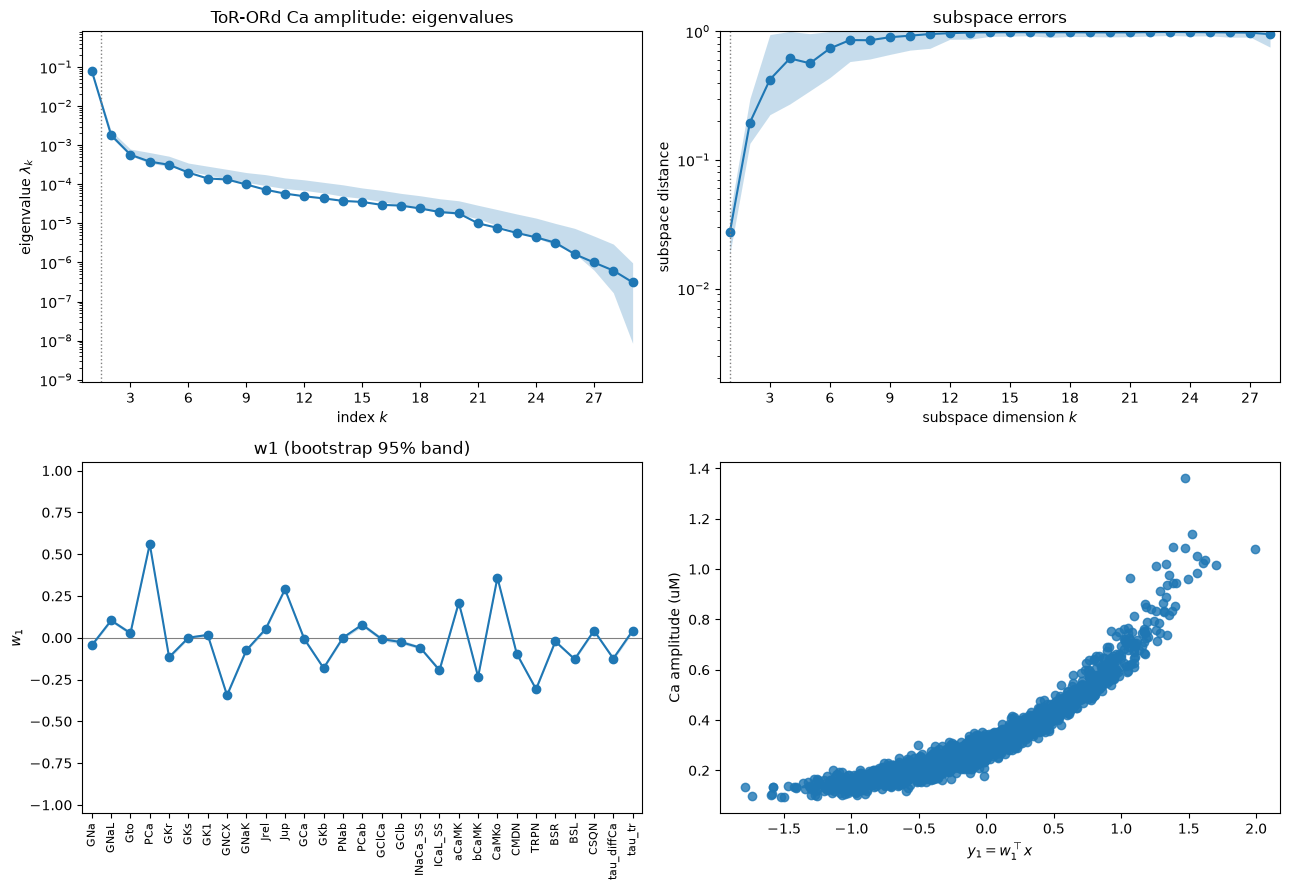

In [16]:
CH = 'Ca_ampl'
jc = CQOIS.index(CH)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ac.plotting.plot_eigenvalues(csubs[CH], ax=axes[0, 0])
axes[0, 0].set_title('ToR-ORd Ca amplitude: eigenvalues')
ac.plotting.plot_subspace_errors(csubs[CH], ax=axes[0, 1])
axes[0, 1].set_title('subspace errors')
ac.plotting.plot_eigenvectors(csubs[CH], indices=[0], labels=CNAMES, interval='percentile', ax=axes[1, 0])
axes[1, 0].tick_params(axis='x', labelrotation=90, labelsize=8)
axes[1, 0].set_title('w1 (bootstrap 95% band)')
ac.plotting.plot_sufficient_summary(csubs[CH], X=XC, f=FC[:, jc], qoi_label='Ca amplitude (uM)', ax=axes[1, 1])
fig.tight_layout()
plt.close(fig)
s = csubs[CH]
print('eigenvalues 1-4:', np.array2string(s.eigenvalues[:4], precision=4))
print('bootstrap mean subspace distance k = 1..4:', np.array2string(s.bootstrap_distances.mean(0)[:4], precision=3))
w = s.W[:, 0]
kept = ['PCa', 'GNCX', 'TRPN']
print('share of |w1|^2 on PCa, GNCX, TRPN (the ToR-ORd inputs kept in the 45):',
      f'{sum(w[CNAMES.index(n)]**2 for n in kept):.3f}')
for q in CQOIS:
    wq = csubs[q].W[:, 0]
    rank = np.argsort(-np.abs(wq))
    print(f'{q:9s} ranks of PCa, GNCX, TRPN in |w1|: ' + ', '.join(str(int(np.where(rank == CNAMES.index(n))[0][0]) + 1) for n in kept)
          + f'; top 5: ' + ', '.join(CNAMES[i] for i in rank[:5]))
sc = ac.fit_surrogate(X=XC, f=FC[:, jc], subspace=s, kind='poly', degree=3)
print(f'Ca_ampl: LOO R^2 of a cubic in y1 = {sc.loo_r_squared:.3f}')
fig

Calcium amplitude grows mainly with the L-type channel conductance $P_{Ca}$ (+0.56) and falls with $G_{NCX}$
and $[TRPN]$; the three ToR-ORd inputs that survived all screening stages into the 45 ($P_{Ca}$, $G_{NCX}$,
$[TRPN]$) carry 0.527 of $\|w_1\|^2$ and rank 1, 3 and 4. $J_{up}$ and $CaMK_o$, which rank high for the
timing features, were dropped at the later tension stage. Along $y_1$ the amplitude grows convexly (the
sufficient summary plot); a cubic in $y_1$ has LOO $R^2$ 0.955 for Ca_ampl. *Caveat:* this subspace belongs to
the ionic box around the ToR-ORd defaults. The four-chamber runs use a different cell region (disjoint
$G_{NCX}$ range, $P_{Ca}$ and $[TRPN]$ up to 1.838 and 1.754 of their defaults), so the 0.527 share describes the
screening stage, not the cells of the four-chamber study.

## Comparison with the paper

The paper reports no active subspace. Its sensitivity analysis gives total-order Sobol' indices from Gaussian
process emulators of the four-chamber outputs (Figs 8–10: bars ranked by $S_T$ and signed by the direction of
the effect). The cell compares, for the 18 outputs in those figures, the paper's two top-ranked inputs with
the two largest entries of the OLS $w_1$ (the activity score for $n = 1$ is $\propto w_1^2$). The paper's
values are read from the figures and approximate. Table 4's emulator $R^2$ (5-fold cross-validation) is
compared with the linear LOO $R^2$. The paper signs each bar by "the sign of the linear regression coefficients
$\beta_i$" of its GPE's linear prior mean (p. 18; the paper cites Eq (4), the covariance, but the linear mean is
Eq (3), p. 12), fitted to the same 407 runs, so agreement in sign with the OLS $w_1$ is close to automatic
and is not independent evidence; only the ranking is a real comparison. The figure captions say red is
positive and blue negative; the text on p. 19 says blue is positive and red negative, which agrees with the
bars (blue bars point up for effects the text calls positive, e.g. $R_{sys}$ on LV peak pressure, p. 22). The
signs here follow the bars and the text.

In [17]:
# Top two inputs of each output in Figs 8-10 of the paper (bars ranked by total-order index, signed by
# the direction of the effect), read from the figures; the value is the top bar's height, approximate.
PAPER_TOP = {
    'EDV_LV': ('EDPshift_LV', -0.39, 'Rpulm', -1), 'EDP_LV': ('Rpulm', -0.34, 'Rsys', +1),
    'EDV_RV': ('EDPunload_RV', -0.52, 'Rsys', -1), 'EDP_RV': ('Rsys', -0.44, 'AVdelay', -1),
    'ESV_LA': ('Rpulm', -0.21, 'Rsys', +1), 'pmax_LA': ('Rpulm', -0.50, 'Rsys', +1),
    'ESV_RA': ('nTRPN_a', +0.15, 'ca50_a', +1), 'pmax_RA': ('Rsys', -0.58, 'phi_a', +1),
    'pmax_LV': ('Rsys', +0.62, 'Rpulm', -1), 'ESV_LV': ('Rsys', +0.38, 'EDPshift_LV', -1),
    'pmax_RV': ('Rpulm', +0.52, 'Rsys', -1), 'ESV_RV': ('EDPunload_RV', -0.44, 'Rpulm', +1),
    'EDVvwave_LA': ('Rpulm', -0.58, 'bt_a', -1), 'EDVvwave_RA': ('Rsys', -0.63, 'bt_a', -1),
    'dpdt_max_LV': ('Rsys', +0.27, 'rs_v', -1), 'dpdt_min_LV': ('Rsys', -0.29, 'rs_v', +1),
    'dpdt_max_RV': ('Rpulm', +0.72, 'rs_v', -1), 'dpdt_min_RV': ('Rpulm', -0.58, 'Rsys', +1),
}
n_top = n_sign = n_two = 0
print(f"{'QoI':12s} {'paper top (ST)':20s} {'notebook top (w1)':20s} {'paper 2nd':14s} {'notebook 2nd':14s} rank of paper top")
for q, (p1, st1, p2, s2) in PAPER_TOP.items():
    w = subs[q].W[:, 0]                                # OLS direction; activity score ~ w1^2 for n = 1
    order = np.argsort(-np.abs(w))
    a, b = order[0], order[1]
    n_top += NAMES[a] == p1
    n_sign += NAMES[a] == p1 and np.sign(w[a]) == np.sign(st1)
    n_two += {NAMES[a], NAMES[b]} == {p1, p2}
    rank = int(np.where(order == NAMES.index(p1))[0][0]) + 1
    print(f"{q:12s} {p1 + f' {st1:+.2f}':20s} {NAMES[a] + f' {w[a]:+.2f}':20s} "
          f"{p2 + (' +' if s2 > 0 else ' -'):14s} {NAMES[b] + (' +' if w[b] > 0 else ' -'):14s} {rank}")
print(f'\nsame top input: {n_top} of {len(PAPER_TOP)} (same sign: {n_sign}); same top two (any order): {n_two}')
TABLE4 = {'EDV_LV': 0.9547, 'EDP_LV': 0.8982, 'ESV_LV': 0.9755, 'pmax_LV': 0.9648, 'dpdt_max_LV': 0.9460,
          'dpdt_min_LV': 0.8901, 'EDV_RV': 0.9755, 'EDP_RV': 0.8815, 'ESV_RV': 0.9852, 'pmax_RV': 0.9671,
          'dpdt_max_RV': 0.8250, 'dpdt_min_RV': 0.8250, 'EDV_LA': 0.8766, 'ESV_LA': 0.8938, 'pmax_LA': 0.9258,
          'EDVvwave_LA': 0.9717, 'EDV_RA': 0.8138, 'ESV_RA': 0.7627, 'pmax_RA': 0.8558, 'EDVvwave_RA': 0.9772}
d = np.array([LIN[q]['loo'] - TABLE4[q] for q in QOIS])
print(f'linear LOO R^2 minus the GPE 5-fold R^2 of Table 4: {d.min():+.3f} to {d.max():+.3f} '
      f'(linear higher for {int(np.sum(d > 0))} of 20)')
print(f"pmax_LV: GPE R^2 {TABLE4['pmax_LV']}, linear LOO {LIN['pmax_LV']['loo']:.3f}, quadratic LOO {RQ['pmax_LV']['loo']:.3f}")
print(f'\nrun time {time.perf_counter() - t_start:.0f} s')

QoI          paper top (ST)       notebook top (w1)    paper 2nd      notebook 2nd   rank of paper top
EDV_LV       EDPshift_LV -0.39    EDPshift_LV -0.49    Rpulm -        Rpulm -        1
EDP_LV       Rpulm -0.34          Rpulm -0.45          Rsys +         ca50_a -       1
EDV_RV       EDPunload_RV -0.52   EDPunload_RV -0.68   Rsys -         Rsys -         1
EDP_RV       Rsys -0.44           Rsys -0.52           AVdelay -      ca50_a -       1
ESV_LA       Rpulm -0.21          ca50_a +0.44         Rsys +         TRPN50_a +     5
pmax_LA      Rpulm -0.50          Rpulm -0.59          Rsys +         Rsys +         1
ESV_RA       nTRPN_a +0.15        ca50_a +0.48         ca50_a +       TRPN50_a +     4
pmax_RA      Rsys -0.58           Rsys -0.51           phi_a +        ca50_a -       1
pmax_LV      Rsys +0.62           Rsys +0.63           Rpulm -        ca50_v -       1
ESV_LV       Rsys +0.38           Rsys +0.53           EDPshift_LV -  EDPshift_LV -  1
pmax_RV      Rpulm +0.52   

The OLS direction has the paper's top-ranked input first for 15 of the 18 outputs and the same top two inputs
for 10. All 15 also have the same sign, but that follows nearly by construction (both signs come from a linear
regression on the same 407 runs). The three differences are informative rather than contradictory. For
dpdt_max_LV the top two are swapped ($rs_v$ −0.40 and $R_{sys}$ +0.38 in $w_1$; with the sd scaling $R_{sys}$
leads, as in Fig. 10). For the two atrial end-systolic volumes the notebook puts atrial cell parameters first
($ca_{50,a}$, $TRPN_{50,a}$, $g_{CaL,a}$, $n_{TRPN,a}$): for ESV_RA the paper does too ($n_{TRPN,a}$ first,
fourth in $w_1$), while for ESV_LA the paper ranks $R_{pulm}$ first ($S_T \approx 0.21$, fifth in $w_1$) with
atrial cell parameters in places 3–6. These are the two outputs where the weights of the correlated cell-model
inputs overstate their joint variance share most (0.306 and 0.667 against separate sums of 2.293 and 5.279);
the paper's Sobol' indices are computed on the HM region itself. Likewise, where the second inputs differ, the
notebook's second is a correlated cell parameter ($ca_{50,a}$, $ca_{50,v}$, $T_{ref,v}$, $rs_v$) where the
paper's is a circulation or timing parameter. The $w_1$ entries and the total-order indices are different
quantities (a direction cosine of the mean linear slope against a variance fraction of the emulator, computed
on the paper's own screened Saltelli design), so only rankings are compared. The linear LOO $R^2$ is below the
emulators' cross-validated $R^2$ for 18 of 20 outputs (by up to 0.157, for dpdt_max_LV) and above it for
EDV_RA and dpdt_min_RV.

| quantity | paper | notebook |
|---|---|---|
| runs (four-chamber), inputs | 407 of 500, m = 45 (pp. 16–17) | 407 × 45 (failures under-represent low $a_v$, $a_a$, $b_{f,a}$, $AV_{delay}$) |
| top input of LV peak pressure | $R_{sys}$, $S_T \approx 0.62$, positive (Fig 9) | $R_{sys}$, $w_1$ entry +0.635; 0.711 of Var($u^\top z$) |
| same top input, 18 outputs of Figs 8–10 | – | 15 of 18 (same sign: 15, nearly by construction) |
| same top two inputs | – | 10 of 18 |
| emulator / surrogate $R^2$, LV peak pressure | 0.9648 (GPE, 5-fold, Table 4) | 0.938 (linear LOO = 1-D polynomial in $y_1$, $w_1$ refitted per fold), 0.955 (penalized quadratic LOO) |
| $R^2$ over the 20 outputs | 0.7627–0.9852 (GPE, Table 4) | 0.731–0.963 (linear LOO) |
| active subspace | not reported | one OLS direction per output; $\lambda_1/\lambda_2$ not identified by the data (penalized quadratic, LV peak pressure: 140.6–684.7 over LOO-equivalent penalties) |
| second direction, EDP_LV and EDP_RV | $AV_{delay}$ second for EDP_RV (Fig 8) | $w_2$ = $AV_{delay}$; LOO $R^2$ +0.038 and +0.089 with $z_{AV}^2$ |
| ToR-ORd parameters kept (29 → 10 → 3 in the 45) | $P_{Ca}$, $G_{NCX}$, $[TRPN]$ (Table 1) | 0.527 of $\|w_1\|^2$ of Ca amplitude (ionic box; $G_{NCX}$ range disjoint from the four-chamber runs) |
| ToR-ORd calcium features, active subspace | not reported | $n = 1$ for all 4, $\lambda_1/\lambda_2$ = 14.4–50.7; stable CaMK $w_2$ for Ca_diast and RT90_Ca |

The paper's text disagrees with itself on one sign: p. 19 says that the EDV of the ventricles was "negatively
affected" by $R_{sys}$ and $R_{pulm}$, and in the next sentences that "the systemic resistance increased the LV
EDV". Fig. 8 and the notebook ($R_{sys}$ +0.32 in $w_1$ of EDV_LV) agree with the second statement.

## References

- M. Strocchi, S. Longobardi, C. M. Augustin, M. A. F. Gsell, A. Petras, C. A. Rinaldi, E. J. Vigmond,
  G. Plank, C. J. Oates, R. D. Wilkinson, S. A. Niederer. Cell to whole organ global sensitivity analysis on a
  four-chamber heart electromechanics model using Gaussian processes emulators. *PLOS Computational Biology*
  19(6):e1011257, 2023. [doi:10.1371/journal.pcbi.1011257](https://doi.org/10.1371/journal.pcbi.1011257).
  Data: [doi:10.5281/zenodo.7405335](https://doi.org/10.5281/zenodo.7405335).
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- J. Tomek, A. Bueno-Orovio, E. Passini, X. Zhou, A. Minchole, O. Britton, C. Bartolucci, S. Severi, A. Shrier,
  L. Virag, A. Varro, B. Rodriguez. Development, calibration, and validation of a novel human ventricular
  myocyte model in health, disease, and drug block. *eLife* 8:e48890, 2019.
  [doi:10.7554/eLife.48890](https://doi.org/10.7554/eLife.48890).
- M. Courtemanche, R. J. Ramirez, S. Nattel. Ionic mechanisms underlying human atrial action potential
  properties: insights from a mathematical model. *American Journal of Physiology-Heart and Circulatory
  Physiology* 275(1):H301–H321, 1998.
  [doi:10.1152/ajpheart.1998.275.1.H301](https://doi.org/10.1152/ajpheart.1998.275.1.H301).
- S. Land, S.-J. Park-Holohan, N. P. Smith, C. G. dos Remedios, J. C. Kentish, S. A. Niederer. A model of
  cardiac contraction based on novel measurements of tension development in human cardiomyocytes. *Journal of
  Molecular and Cellular Cardiology* 106:68–83, 2017.
  [doi:10.1016/j.yjmcc.2017.03.008](https://doi.org/10.1016/j.yjmcc.2017.03.008).
- T. Arts, T. Delhaas, P. Bovendeerd, X. Verbeek, F. W. Prinzen. Adaptation to mechanical load determines
  shape and properties of heart and circulation: the CircAdapt model. *American Journal of Physiology-Heart
  and Circulatory Physiology* 288(4):H1943–H1954, 2005.
  [doi:10.1152/ajpheart.00444.2004](https://doi.org/10.1152/ajpheart.00444.2004).
- S. Longobardi, A. Lewalle, S. Coveney, I. Sjaastad, E. K. S. Espe, W. E. Louch, C. J. Musante, A. Sher,
  S. A. Niederer. Predicting left ventricular contractile function via Gaussian process emulation in
  aortic-banded rats. *Philosophical Transactions of the Royal Society A* 378(2173):20190334, 2020.
  [doi:10.1098/rsta.2019.0334](https://doi.org/10.1098/rsta.2019.0334).

## Acknowledgments

From the paper: SAN is supported by the Wellcome/EPSRC Centre for Medical Engineering (WT 203148/Z/16/Z),
NIH R01-HL152256, ERC PREDICT-HF 453 (864055), BHF (RG/20/4/34803), EPSRC (EP/P01268X/1) and by the Technology
Missions Fund under the EPSRC Grant EP/X03870X/1 & The Alan Turing Institute. EJV received financial support
from the French Government as part of the "Investments of the Future" program managed by the National
Research Agency (ANR) (ANR-10-IAHU-04). CMA received funding from the European Union's Horizon 2020 research
and innovation programme under the ERA-NET co-fund action No. 680969 (ERA-CVD SICVALVES) funded by the
Austrian Science Fund (FWF), Grant I 4652-B. AP was partially supported by the State of Upper Austria.
The data are the authors' (Zenodo, CC BY 4.0); this notebook only analyses them.